# **Laboratorio 3**

## Integrantes:
- Laura Sanchez Bernal - 202411353
- Baruc Jeronimo Triana Bastidas - 202416093

## Planteamiento del problema

Ruta Alpes busca anticipar si un conductor aceptará un cupón para ofrecer recomendaciones más relevantes. Se plantea una tarea de clasificación supervisada con la variable objetivo `acepta_cupon`.

Se construyen modelos separados para Cafetería y Restaurante(<20), utilizando regresión logística, árboles de decisión y Random Forest. La categoría "Sí" se considera la clase positiva.

La selección de hiperparámetros y del algoritmo final se realizará con el F1-score de aceptación obtenido mediante validación cruzada sobre entrenamiento. El conjunto de prueba se utilizará para reportar el desempeño. También se revisarán el F1-score macro y el recall de rechazo, especialmente en Restaurante(<20), donde las clases están desbalanceadas.

# 1. Exploración y calidad de datos
En esta etapa se realiza una exploración inicial del conjunto de datos para identificar las características de las variables, los tipos de datos y posibles problemas de calidad. Esta revisión permitirá determinar qué procedimientos de preparación serán necesarios antes de entrenar los modelos de clasificación.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone

In [2]:
datos = pd.read_excel('./Data/Lab3_Datos.xlsx')
datos.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


In [3]:
data = datos.copy()

In [4]:
data.shape

(12664, 26)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12664 entries, 0 to 12663
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   destino                          12664 non-null  object
 1   acompanante                      12664 non-null  object
 2   clima                            12664 non-null  object
 3   temperatura                      12664 non-null  int64 
 4   hora                             12664 non-null  object
 5   cupon                            12664 non-null  object
 6   vigencia_cupon                   12664 non-null  object
 7   genero                           12664 non-null  object
 8   edad                             12664 non-null  object
 9   estado_civil                     12664 non-null  object
 10  tiene_hijos                      12664 non-null  object
 11  educacion                        12664 non-null  object
 12  ocupacion                       

### 1.1. Estructura del conjunto de datos

El conjunto de datos contiene 12.664 registros y 26 variables, de las cuales 25 son de tipo texto y una es numérica.

La variable objetivo, `acepta_cupon`, no presenta valores nulos. Sin embargo, se identifican datos faltantes en algunas variables relacionadas con las características del conductor y sus hábitos de consumo.

La variable `vehiculo` presenta una cantidad especialmente alta de valores faltantes, pues solamente cuenta con 108 registros no nulos. Por esta razón, será necesario evaluar su calidad y utilidad antes de decidir si debe incluirse en los modelos.

También será necesario analizar por separado los registros correspondientes a los cupones de Cafetería y Restaurante(<20), de acuerdo con los objetivos del laboratorio.

In [6]:
((data.isnull().sum()/data.shape[0])).sort_values(ascending=False)

vehiculo                           0.991472
frecuencia_cafeteria               0.017135
frecuencia_restaurante_20_a_50     0.014924
frecuencia_comida_para_llevar      0.011924
frecuencia_restaurante_menos_20    0.010265
frecuencia_bar                     0.008449
destino                            0.000000
acompanante                        0.000000
direccion_opuesta                  0.000000
misma_direccion                    0.000000
tiempo_cupon_mayor_25min           0.000000
tiempo_cupon_mayor_15min           0.000000
tiempo_cupon_mayor_5min            0.000000
ingreso                            0.000000
ocupacion                          0.000000
educacion                          0.000000
tiene_hijos                        0.000000
estado_civil                       0.000000
edad                               0.000000
genero                             0.000000
vigencia_cupon                     0.000000
cupon                              0.000000
hora                            

### 1.2. Análisis de valores faltantes

Se identificaron seis variables con valores faltantes. La variable `vehiculo` presenta el mayor porcentaje (99,15 %), mientras que las cinco variables relacionadas con la frecuencia de consumo tienen porcentajes de valores faltantes entre el 0,84 % y el 1,71 %.

La cantidad de información faltante en `vehiculo` podría afectar su utilidad para el entrenamiento de los modelos. Por esta razón, se evaluará su exclusión durante la preparación de los datos.

En cuanto a las variables de frecuencia de consumo, se analizarán sus distribuciones antes de definir el tratamiento de los valores faltantes, buscando conservar la mayor cantidad posible de información relevante.

Las demás variables no presentan valores faltantes.

In [7]:
int(data.duplicated(keep=False).sum())

148

### 1.3. Análisis de unicidad

Se identificaron 148 registros que presentan coincidencias exactas con al menos otro registro del conjunto de datos.

Este resultado evidencia la presencia de observaciones duplicadas. Sin embargo, no necesariamente corresponde a 148 registros adicionales, debido a que el procedimiento utilizado cuenta todas las apariciones de las filas repetidas.

Antes de decidir su eliminación, es necesario considerar que diferentes conductores podrían presentar las mismas características y respuestas. Por esta razón, se evaluará el tratamiento de estos registros durante la etapa de preparación de los datos.

In [8]:
data['acepta_cupon'].value_counts()

acepta_cupon
Sí    7196
No    5468
Name: count, dtype: int64

### 1.4. Distribución de la variable objetivo

La variable objetivo `acepta_cupon` presenta 7.196 registros correspondientes a la categoría "Sí" (56,82 %) y 5.468 registros correspondientes a la categoría "No" (43,18 %).

Se observa una mayor proporción de aceptación de cupones, aunque ambas clases tienen una representación considerable en el conjunto de datos.

No obstante, esta distribución corresponde a todos los tipos de cupón. Por lo tanto, es necesario analizar las clases por separado para los cupones de Cafetería y Restaurante(<20), que son los utilizados en el laboratorio.

El balanceo de clases se evaluará posteriormente, conforme a las indicaciones del enunciado y las técnicas presentadas en la práctica P9.

### 1.5. Análisis por tipo de cupón

El laboratorio se enfoca en dos tipos de cupones: Cafetería y Restaurante(<20). Por esta razón, se crean dos subconjuntos de datos para analizar sus características y la distribución de la variable objetivo de manera independiente.

Esta separación permitirá identificar posibles diferencias entre los conductores que aceptan o rechazan cada tipo de cupón y servirá como base para construir los modelos de clasificación solicitados.

In [9]:
data_cafeteria = data[data['cupon'] == 'Cafetería'].copy()
data_restaurante = data[data['cupon'] == 'Restaurante(<20)'].copy()

print("Cafetería:")
print(data_cafeteria.shape)
print(data_cafeteria['acepta_cupon'].value_counts())

print("\nRestaurante(<20):")
print(data_restaurante.shape)
print(data_restaurante['acepta_cupon'].value_counts())

Cafetería:
(3986, 26)
acepta_cupon
No    1997
Sí    1989
Name: count, dtype: int64

Restaurante(<20):
(2776, 26)
acepta_cupon
Sí    1962
No     814
Name: count, dtype: int64


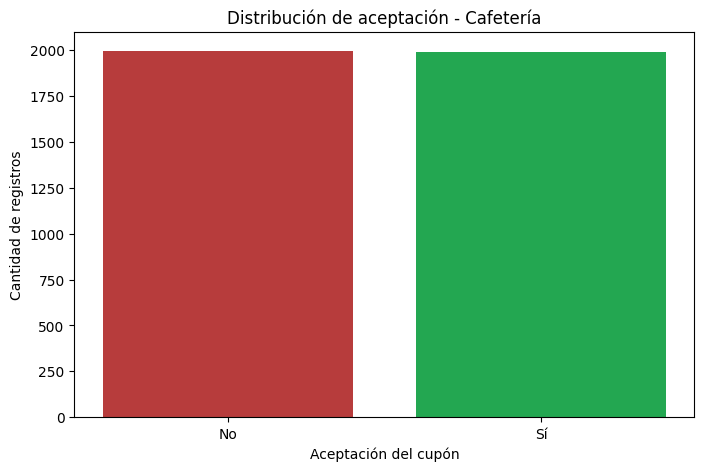

In [10]:
plt.figure(figsize=(8, 5))

plot_data = data_cafeteria['acepta_cupon'].value_counts()

x = plot_data.index
y = plot_data.values

plt.bar(x, y, color=["#B73C3C", "#23A751"])

plt.xlabel("Aceptación del cupón")
plt.ylabel("Cantidad de registros")
plt.title("Distribución de aceptación - Cafetería")

plt.show()

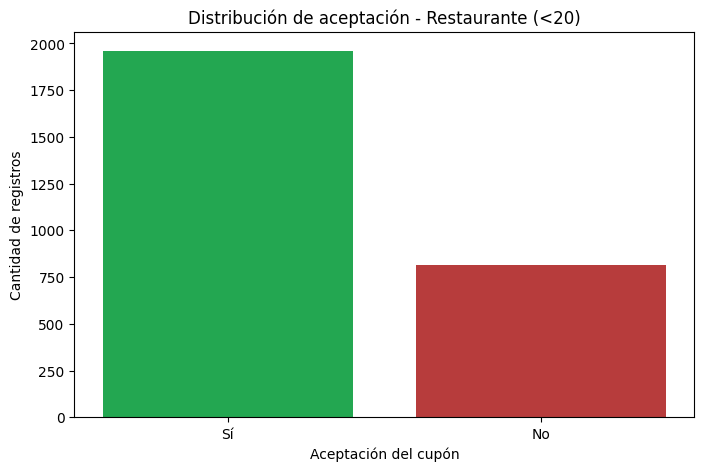

In [11]:
plt.figure(figsize=(8, 5))

plot_data = data_restaurante['acepta_cupon'].value_counts()

x = plot_data.index
y = plot_data.values

plt.bar(x, y, color=["#23A751", "#B73C3C"])

plt.xlabel("Aceptación del cupón")
plt.ylabel("Cantidad de registros")
plt.title("Distribución de aceptación - Restaurante (<20)")

plt.show()

### 1.6. Distribución de la variable objetivo por tipo de cupón

Para Cafetería se identificaron 3.986 registros, de los cuales 1.989 corresponden a personas que aceptaron el cupón (49,9 %) y 1.997 a personas que lo rechazaron (50,1 %). Esto indica que las clases se encuentran prácticamente equilibradas.

Para Restaurante(<20) se identificaron 2.776 registros, de los cuales 1.962 corresponden a aceptación (70,7 %) y 814 a rechazo (29,3 %). En este caso se observa un desbalance a favor de la clase "Sí".

Esta diferencia es importante para el entrenamiento y la evaluación de los modelos, pues una mayor representación de una clase puede influir en las predicciones. Por esta razón, se evaluará el efecto de SMOTE en los modelos de Restaurante(<20), siguiendo lo estudiado en la práctica P9.

En ambos casos se utilizarán métricas de evaluación que permitan analizar el desempeño de los modelos más allá de la exactitud global.

In [12]:
data_cafeteria.describe(include='all')

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,3986,3986,3986,3986.000000,3986,3986,3986,3986,3986,3986,...,3914,3929,3936,3931,3986,3986,3986,3986,3986,3986
unique,3,4,3,NaN,5,1,2,2,8,5,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,NaN,6:00 p.m.,Cafetería,2 horas,Femenino,21,Soltero(a),...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,Sí,No,No,Sí,No
freq,2151,2251,3459,NaN,1091,3986,2222,2045,882,1545,...,1073,1493,1677,1864,3986,2069,3676,3239,3239,1997
mean,NaN,NaN,NaN,68.026844,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,15.992518,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
data_restaurante.describe(include='all')

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,2776,2776,2776,2776.000000,2776,2776,2776,2776,2776,2776,...,2729,2742,2749,2733,2776,2776,2776,2776,2776,2776
unique,3,4,3,NaN,5,1,2,2,8,5,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,NaN,6:00 p.m.,Restaurante(<20),2 horas,Femenino,21,Casado(a),...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,No,No,No,Sí,Sí
freq,1707,1431,2231,NaN,744,2776,1427,1417,569,1114,...,734,1018,1151,1328,2776,1535,2466,2275,2275,1962
mean,NaN,NaN,NaN,64.176873,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,19.790289,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.7. Análisis descriptivo de los subconjuntos

Se realizó un análisis descriptivo de los conjuntos de datos correspondientes a Cafetería y Restaurante(<20), utilizando estadísticas de tendencia central y frecuencia de las variables.

En ambos conjuntos, el destino más frecuente es "Sin lugar urgente", el acompañante más común es "Solo", el clima predominante es "Soleado" y la hora más frecuente es las 6:00 p. m.

La temperatura promedio es de 68,03 °F para Cafetería y 64,18 °F para Restaurante(<20), mientras que la mediana es de 80 °F en ambos conjuntos. Según el diccionario, esta variable representa condiciones de la encuesta y solamente toma los valores 30, 55 y 80 °F. Por esta razón, estos valores no se consideran errores ni se eliminan como valores atípicos.

También se identifican diferencias en el estado civil más frecuente: "Soltero(a)" para Cafetería y "Casado(a)" para Restaurante(<20).

Estos resultados permiten describir las características generales de las observaciones. Sin embargo, será necesario continuar con la preparación y el modelado para evaluar la relación de las variables con la aceptación de los cupones.

In [14]:
# Valores faltantes - Cafetería
(data_cafeteria.isnull().sum() / data_cafeteria.shape[0]).sort_values(ascending=False)

vehiculo                           0.990718
frecuencia_cafeteria               0.018063
frecuencia_comida_para_llevar      0.014300
frecuencia_restaurante_20_a_50     0.013798
frecuencia_restaurante_menos_20    0.012544
frecuencia_bar                     0.009282
destino                            0.000000
acompanante                        0.000000
direccion_opuesta                  0.000000
misma_direccion                    0.000000
tiempo_cupon_mayor_25min           0.000000
tiempo_cupon_mayor_15min           0.000000
tiempo_cupon_mayor_5min            0.000000
ingreso                            0.000000
ocupacion                          0.000000
educacion                          0.000000
tiene_hijos                        0.000000
estado_civil                       0.000000
edad                               0.000000
genero                             0.000000
vigencia_cupon                     0.000000
cupon                              0.000000
hora                            

In [15]:
# Valores faltantes - Restaurante (<20)
(data_restaurante.isnull().sum() / data_restaurante.shape[0]).sort_values(ascending=False)

vehiculo                           0.990994
frecuencia_cafeteria               0.016931
frecuencia_restaurante_20_a_50     0.015490
frecuencia_comida_para_llevar      0.012248
frecuencia_restaurante_menos_20    0.009726
frecuencia_bar                     0.008285
destino                            0.000000
acompanante                        0.000000
direccion_opuesta                  0.000000
misma_direccion                    0.000000
tiempo_cupon_mayor_25min           0.000000
tiempo_cupon_mayor_15min           0.000000
tiempo_cupon_mayor_5min            0.000000
ingreso                            0.000000
ocupacion                          0.000000
educacion                          0.000000
tiene_hijos                        0.000000
estado_civil                       0.000000
edad                               0.000000
genero                             0.000000
vigencia_cupon                     0.000000
cupon                              0.000000
hora                            

### 1.8. Análisis de completitud por tipo de cupón

Se evaluó la proporción de valores faltantes en los conjuntos de Cafetería y Restaurante(<20).

En ambos casos, la variable `vehiculo` presenta más del 99 % de valores faltantes, lo que limita considerablemente su utilidad para el entrenamiento de los modelos.

Por otra parte, las variables relacionadas con la frecuencia de consumo presentan porcentajes de datos faltantes inferiores al 2 %, con pequeñas diferencias entre ambos conjuntos.

Debido a estos resultados, se considera pertinente evaluar la exclusión de la variable `vehiculo` y estudiar alternativas para tratar los valores faltantes de las variables de frecuencia de consumo, siguiendo los procedimientos de preparación de datos de la práctica P2.

Las decisiones definitivas de limpieza se tomarán en la siguiente etapa, buscando conservar información útil para la clasificación.

In [16]:
columnas_frecuencia = [
    'frecuencia_bar',
    'frecuencia_cafeteria',
    'frecuencia_comida_para_llevar',
    'frecuencia_restaurante_menos_20',
    'frecuencia_restaurante_20_a_50'
]

for columna in columnas_frecuencia:
    print("\nVariable:", columna)
    print("Cafetería:")
    print(data_cafeteria[columna].value_counts())
    print("Restaurante (<20):")
    print(data_restaurante[columna].value_counts())


Variable: frecuencia_bar
Cafetería:
frecuencia_bar
nunca         1634
menos de 1    1072
1 a 3          760
4 a 8          370
más de 8       113
Name: count, dtype: int64
Restaurante (<20):
frecuencia_bar
nunca         1118
menos de 1     761
1 a 3          557
4 a 8          238
más de 8        79
Name: count, dtype: int64

Variable: frecuencia_cafeteria
Cafetería:
frecuencia_cafeteria
menos de 1    1073
1 a 3         1038
nunca          925
4 a 8          537
más de 8       341
Name: count, dtype: int64
Restaurante (<20):
frecuencia_cafeteria
menos de 1    734
1 a 3         712
nunca         648
4 a 8         387
más de 8      248
Name: count, dtype: int64

Variable: frecuencia_comida_para_llevar
Cafetería:
frecuencia_comida_para_llevar
1 a 3         1493
4 a 8         1338
menos de 1     572
más de 8       484
nunca           42
Name: count, dtype: int64
Restaurante (<20):
frecuencia_comida_para_llevar
1 a 3         1018
4 a 8          949
menos de 1     396
más de 8       345
nun

In [17]:
for columna in columnas_frecuencia:
    print("Variable:", columna)
    print("Moda Cafetería:",
          data_cafeteria[columna].mode().iloc[0])
    print("Moda Restaurante:",
          data_restaurante[columna].mode().iloc[0])
    print()

Variable: frecuencia_bar
Moda Cafetería: nunca
Moda Restaurante: nunca

Variable: frecuencia_cafeteria
Moda Cafetería: menos de 1
Moda Restaurante: menos de 1

Variable: frecuencia_comida_para_llevar
Moda Cafetería: 1 a 3
Moda Restaurante: 1 a 3

Variable: frecuencia_restaurante_menos_20
Moda Cafetería: 1 a 3
Moda Restaurante: 1 a 3

Variable: frecuencia_restaurante_20_a_50
Moda Cafetería: menos de 1
Moda Restaurante: menos de 1



### 1.9. Revisión de consistencia y redundancia

Además de los valores faltantes, se revisan las categorías de frecuencia de consumo, los valores de temperatura y la coherencia entre los tiempos de desplazamiento.

También se cuentan las repeticiones exactas adicionales y se compara `misma_direccion` con `direccion_opuesta` para identificar información redundante.

In [18]:
frecuencias_validas = [
    'nunca',
    'menos de 1',
    '1 a 3',
    '4 a 8',
    'más de 8'
]

resumen_calidad = []

for nombre, subconjunto in [
    ('Cafetería', data_cafeteria),
    ('Restaurante(<20)', data_restaurante)
]:
    frecuencias_invalidas = sum(
        (
            subconjunto[columna].notna()
            & ~subconjunto[columna].isin(frecuencias_validas)
        ).sum()
        for columna in columnas_frecuencia
    )

    tiempos_inconsistentes = (
        (subconjunto['tiempo_cupon_mayor_25min'] == 'Sí')
        & (subconjunto['tiempo_cupon_mayor_15min'] == 'No')
    ).sum()

    resumen_calidad.append({
        'Cupón': nombre,
        'Duplicados adicionales': subconjunto.duplicated().sum(),
        'Frecuencias inválidas': frecuencias_invalidas,
        'Temperaturas inválidas': (
            ~subconjunto['temperatura'].isin([30, 55, 80])
        ).sum(),
        'Objetivos inválidos': (
            ~subconjunto['acepta_cupon'].isin(['No', 'Sí'])
        ).sum(),
        'Tiempos inconsistentes': tiempos_inconsistentes
    })

    print(f"\nRelación entre las variables de dirección: {nombre}")
    display(pd.crosstab(
        subconjunto['misma_direccion'],
        subconjunto['direccion_opuesta']
    ))

display(pd.DataFrame(resumen_calidad))


Relación entre las variables de dirección: Cafetería


direccion_opuesta,No,Sí
misma_direccion,,
No,0,3239
Sí,747,0



Relación entre las variables de dirección: Restaurante(<20)


direccion_opuesta,No,Sí
misma_direccion,,
No,0,2275
Sí,501,0


,Cupón,Duplicados adicionales,Frecuencias inválidas,Temperaturas inválidas,Objetivos inválidos,Tiempos inconsistentes
0,Cafetería,7,0,0,0,0
1,Restaurante(<20),7,0,0,0,0


Se encontraron siete repeticiones exactas adicionales en cada subconjunto. No se identificaron valores inválidos en las frecuencias, la temperatura o la variable objetivo, ni inconsistencias en la relación revisada entre los tiempos de desplazamiento.

Las tablas muestran que `misma_direccion` y `direccion_opuesta` son complementarias: cuando una toma el valor "Sí", la otra toma "No". Por tanto, basta con conservar una de ellas.

Los tiempos superiores a 15 y 25 minutos se mantienen, pues representan condiciones diferentes aunque estén relacionadas.

### 2. Preparación de datos

#### 2.1. Tratamiento de duplicados y valores faltantes

Se conserva una sola aparición de cada fila exactamente repetida, incluyendo su respuesta de aceptación. Esta decisión se toma antes de dividir los datos, para evitar que copias idénticas de una observación queden repartidas entre entrenamiento y prueba.

Como el archivo no incluye un identificador de conductor, no es posible confirmar el origen de las repeticiones. Se adopta su eliminación como una decisión de preparación, sin asumir que esto garantiza la independencia de todos los registros.

Se elimina `vehiculo` porque presenta más del 99 % de valores faltantes.

Para las variables categóricas se utiliza la categoría "Sin información" mediante `SimpleImputer`, siguiendo la preparación presentada en P7. Así se conservan las observaciones sin asignarles artificialmente el hábito de consumo más frecuente.

La imputación se realiza dentro del pipeline. Para la variable numérica se conserva la imputación por mediana y la estandarización.

In [19]:
cafeteria_limpio = (
    data_cafeteria
    .drop_duplicates()
    .drop(columns=['vehiculo'])
    .copy()
)

restaurante_limpio = (
    data_restaurante
    .drop_duplicates()
    .drop(columns=['vehiculo'])
    .copy()
)

print("Cafetería:")
print("Duplicados eliminados:", len(data_cafeteria) - len(cafeteria_limpio))
print("Dimensiones:", cafeteria_limpio.shape)

print("\nRestaurante(<20):")
print("Duplicados eliminados:", len(data_restaurante) - len(restaurante_limpio))
print("Dimensiones:", restaurante_limpio.shape)

Cafetería:
Duplicados eliminados: 7
Dimensiones: (3979, 25)

Restaurante(<20):
Duplicados eliminados: 7
Dimensiones: (2769, 25)


#### Identificación de variables sin variabilidad

Durante la exploración se identificó que las variables `cupon` y `tiempo_cupon_mayor_5min` presentan un único valor en cada uno de los subconjuntos analizados.

La variable `cupon` es constante porque los datos se separaron previamente según el tipo de establecimiento. Por su parte, `tiempo_cupon_mayor_5min` toma el valor "Sí" para todas las observaciones de ambos subconjuntos.

Debido a que estas características no permiten distinguir entre observaciones dentro de cada subconjunto, se propone excluirlas de las variables predictoras.

Esta decisión busca evitar incorporar características sin variabilidad y simplificar la preparación de los datos.

In [20]:
columnas_constantes = [
    'cupon',
    'tiempo_cupon_mayor_5min'
]

print("Cafetería:")
for columna in columnas_constantes:
    print(columna, cafeteria_limpio[columna].unique())

print("\nRestaurante (<20):")
for columna in columnas_constantes:
    print(columna, restaurante_limpio[columna].unique())

Cafetería:
cupon ['Cafetería']
tiempo_cupon_mayor_5min ['Sí']

Restaurante (<20):
cupon ['Restaurante(<20)']
tiempo_cupon_mayor_5min ['Sí']


#### Eliminación de información redundante

Además de las variables constantes `cupon` y `tiempo_cupon_mayor_5min`, se excluye `direccion_opuesta`, porque contiene la misma información que `misma_direccion`, expresada de forma complementaria.

Se conserva `misma_direccion` para representar esta característica del recorrido. Esta decisión permite reducir la redundancia sin perder la información sobre la dirección del establecimiento.

### 2.2. Separación de variables predictoras y variable objetivo

Para cada tipo de cupón se separan las variables predictoras (X) y la variable objetivo (y).

La variable objetivo corresponde a `acepta_cupon`, que indica si el conductor aceptó o rechazó la oferta. Las variables predictoras contienen información sobre las características del conductor y las condiciones del viaje.

Esta separación permitirá preparar los datos y posteriormente entrenar los modelos de clasificación de manera independiente para cada tipo de cupón.

In [21]:
columnas_excluir = [
    'acepta_cupon',
    'cupon',
    'tiempo_cupon_mayor_5min',
    'direccion_opuesta'
]

X_cafeteria = cafeteria_limpio.drop(columns=columnas_excluir)

y_cafeteria = cafeteria_limpio['acepta_cupon'].map({
    'No': 0,
    'Sí': 1
})

X_restaurante = restaurante_limpio.drop(columns=columnas_excluir)

y_restaurante = restaurante_limpio['acepta_cupon'].map({
    'No': 0,
    'Sí': 1
})

assert y_cafeteria.notna().all()
assert y_restaurante.notna().all()

print("Cafetería:")
print("Predictores:", X_cafeteria.shape)
print("Objetivo:", y_cafeteria.shape)

print("\nRestaurante(<20):")
print("Predictores:", X_restaurante.shape)
print("Objetivo:", y_restaurante.shape)

Cafetería:
Predictores: (3979, 21)
Objetivo: (3979,)

Restaurante(<20):
Predictores: (2769, 21)
Objetivo: (2769,)


In [22]:
print("Columnas predictoras de Cafetería:")
print(X_cafeteria.shape)

print("\nColumnas predictoras de Restaurante:")
print(X_restaurante.shape)

Columnas predictoras de Cafetería:
(3979, 21)

Columnas predictoras de Restaurante:
(2769, 21)


### 2.3. División de los datos en entrenamiento y prueba

Se realiza una división de los datos para cada tipo de cupón, destinando el 80 % de las observaciones al entrenamiento y el 20 % a la evaluación de los modelos.

Se utiliza una división estratificada mediante `stratify=y` para conservar aproximadamente la proporción de aceptación y rechazo en ambos conjuntos.

Además, se establece `random_state=1` para garantizar la reproducibilidad de los resultados, siguiendo el procedimiento presentado en la práctica P7 de regresión logística.

Esta separación permite evaluar el desempeño de los modelos sobre observaciones que no fueron utilizadas durante su entrenamiento.

In [23]:
from sklearn.model_selection import train_test_split

# División de datos - Cafetería
X_train_caf, X_test_caf, y_train_caf, y_test_caf = train_test_split(
    X_cafeteria,
    y_cafeteria,
    test_size=0.2,
    random_state=1,
    stratify=y_cafeteria
)

# División de datos - Restaurante (<20)
X_train_res, X_test_res, y_train_res, y_test_res = train_test_split(
    X_restaurante,
    y_restaurante,
    test_size=0.2,
    random_state=1,
    stratify=y_restaurante
)

print("Cafetería:")
print("Entrenamiento:", X_train_caf.shape)
print("Prueba:", X_test_caf.shape)

print("\nRestaurante (<20):")
print("Entrenamiento:", X_train_res.shape)
print("Prueba:", X_test_res.shape)

Cafetería:
Entrenamiento: (3183, 21)
Prueba: (796, 21)

Restaurante (<20):
Entrenamiento: (2215, 21)
Prueba: (554, 21)


### 2.4. Identificación de variables numéricas y categóricas

Se identifican las variables predictoras de acuerdo con sus tipos de datos para aplicar las transformaciones correspondientes.

La variable `temperatura` es numérica, mientras que las demás variables predictoras son categóricas.

Esta distinción permitirá construir un preprocesador que aplique las transformaciones necesarias a cada grupo de variables, siguiendo el procedimiento de la práctica P7.

Las transformaciones se ajustarán utilizando únicamente el conjunto de entrenamiento para evitar que la información del conjunto de prueba influya en el aprendizaje del modelo.

In [24]:
numericas_features = ['temperatura']

categoricas_features = [
    columna
    for columna in X_train_caf.columns
    if columna not in numericas_features
]

print("Variables numéricas:")
print(numericas_features)

print("\nVariables categóricas:")
print(categoricas_features)

print("\nCantidad de variables categóricas:")
print(len(categoricas_features))

Variables numéricas:
['temperatura']

Variables categóricas:
['destino', 'acompanante', 'clima', 'hora', 'vigencia_cupon', 'genero', 'edad', 'estado_civil', 'tiene_hijos', 'educacion', 'ocupacion', 'ingreso', 'frecuencia_bar', 'frecuencia_cafeteria', 'frecuencia_comida_para_llevar', 'frecuencia_restaurante_menos_20', 'frecuencia_restaurante_20_a_50', 'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min', 'misma_direccion']

Cantidad de variables categóricas:
20


### 2.5. Construcción del preprocesador

Se construyen dos pipelines de transformación según el tipo de variable, siguiendo el procedimiento presentado en la práctica P7 de regresión logística.

Para las variables numéricas se utiliza `SimpleImputer` con la estrategia de mediana y posteriormente `StandardScaler`, con el fin de estandarizar sus valores.

Para las variables categóricas se utiliza `SimpleImputer` con la estrategia constante, asignando la categoría "Sin información" a los valores faltantes. Posteriormente se aplica `OneHotEncoder` para transformar las categorías en una representación numérica.

Se utiliza `ColumnTransformer` para integrar ambos procedimientos. Las transformaciones serán ajustadas durante el entrenamiento de los modelos para evitar utilizar información del conjunto de prueba.

In [25]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Transformación de variables numéricas
numerica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Transformación de variables categóricas
categorica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(
        strategy='constant',
        fill_value='Sin información'
    )),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

# Preprocesador
preprocesador = ColumnTransformer(
    transformers=[
        ('num', numerica_transformer, numericas_features),
        ('cat', categorica_transformer, categoricas_features)
    ]
)

### 3. Modelos de clasificación — Regresión logística

#### 3.1. Construcción del pipeline

Se utiliza un modelo de regresión logística para predecir la aceptación de los cupones, siguiendo el procedimiento presentado en la práctica P7.

El modelo se integra en un pipeline junto con las transformaciones definidas anteriormente. Esto permite que la preparación de los datos y el entrenamiento se realicen de forma consistente.

Se establece `max_iter=1000`, siguiendo la configuración de la práctica, para permitir un número suficiente de iteraciones durante la optimización del modelo.

Posteriormente se realizará una búsqueda de hiperparámetros mediante validación cruzada, explorando diferentes tipos de regularización y algoritmos de optimización (solvers), según lo solicitado en el enunciado.

In [26]:
from sklearn.linear_model import LogisticRegression

pipeline_rl = Pipeline(steps=[
    ('preprocesador', clone(preprocesador)),
    ('modelo', LogisticRegression(
        max_iter=1000,
        random_state=1,
        n_jobs=1
    ))
])

pipeline_rl

,steps,"[('preprocesador', ...), ('modelo', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


#### 3.2. Verificación de la variable objetivo

La variable objetivo fue codificada antes de la división de los datos: 1 representa aceptación y 0 representa rechazo.

Se verifica que los cuatro conjuntos del objetivo conserven esa codificación y no contengan valores faltantes. También se revisa la distribución de las clases en entrenamiento.

In [27]:
for objetivo in [
    y_train_caf,
    y_test_caf,
    y_train_res,
    y_test_res
]:
    assert objetivo.notna().all()
    assert objetivo.isin([0, 1]).all()

print("Cafetería - Entrenamiento:")
print(y_train_caf.value_counts().sort_index())

print("\nRestaurante(<20) - Entrenamiento:")
print(y_train_res.value_counts().sort_index())

Cafetería - Entrenamiento:
acepta_cupon
0    1597
1    1586
Name: count, dtype: int64

Restaurante(<20) - Entrenamiento:
acepta_cupon
0     648
1    1567
Name: count, dtype: int64


### 3.3. Selección de hiperparámetros mediante validación cruzada

Para seleccionar la mejor configuración del modelo de regresión logística se utiliza `GridSearchCV`, siguiendo el procedimiento de la práctica P7.

Se exploran las regularizaciones L1 y L2, diferentes algoritmos de optimización y valores del parámetro C.

Se utiliza validación cruzada estratificada de 10 particiones mediante `StratifiedKFold`, para mantener aproximadamente la proporción de las clases durante la evaluación.

La selección se realizará utilizando el F1-score, que combina precisión y recall. Esto permite evaluar el desempeño del modelo considerando tanto los falsos positivos como los falsos negativos.

La búsqueda se realizará únicamente sobre el conjunto de entrenamiento de Cafetería, reservando el conjunto de prueba para la evaluación final.

In [28]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = [
    # Combinaciones válidas con L2
    {
        'modelo__penalty': ['l2'],
        'modelo__solver': ['newton-cg', 'lbfgs', 'liblinear'],
        'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]
    },
    # Combinaciones válidas con L1
    {
        'modelo__penalty': ['l1'],
        'modelo__solver': ['liblinear'],
        'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]
    }
]

kfold = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=0
)

In [29]:
grid_rl_caf = GridSearchCV(
    estimator=pipeline_rl,
    param_grid=param_grid,
    cv=kfold,
    scoring='f1',
    n_jobs=-2
)

grid_rl_caf

,estimator,Pipeline(step...om_state=1))])
,param_grid,"[{'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', ...]}, {'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear']}]"
,scoring,'f1'
,n_jobs,-2
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


### 3.4. Entrenamiento del modelo de regresión logística — Cafetería

Se entrena el modelo de regresión logística utilizando el conjunto de entrenamiento de Cafetería.

Mediante `GridSearchCV` se evalúan las diferentes combinaciones de hiperparámetros definidas anteriormente. La selección se realiza utilizando el F1-score promedio de la validación cruzada estratificada.

El preprocesamiento se ejecuta dentro del pipeline, lo cual permite ajustar las transformaciones con los datos correspondientes a cada partición de entrenamiento y evita utilizar información del conjunto de prueba durante el entrenamiento.

In [30]:
grid_rl_caf.fit(X_train_caf, y_train_caf)

,estimator,Pipeline(step...om_state=1))])
,param_grid,"[{'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', ...]}, {'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear']}]"
,scoring,'f1'
,n_jobs,-2
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [31]:
print("Mejores hiperparámetros:")
print(grid_rl_caf.best_params_)

print("\nMejor F1-score de validación cruzada:")
print(grid_rl_caf.best_score_)

Mejores hiperparámetros:
{'modelo__C': 0.1, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}

Mejor F1-score de validación cruzada:
0.7292048086662589


### 3.5. Resultados de la búsqueda de hiperparámetros — Cafetería

La búsqueda seleccionó regularización L1, C=0.1 y el solver `liblinear`. Esta configuración obtuvo un F1-score promedio de 0,7288 en validación cruzada.

La regularización L1 puede reducir algunos coeficientes a cero, lo que permite controlar la complejidad del modelo. Esta fue la mejor configuración entre las combinaciones evaluadas.

### 3.6. Evaluación del modelo de regresión logística — Cafetería

Una vez seleccionada la mejor configuración mediante validación cruzada, se evalúa el modelo sobre el conjunto de prueba.

Se calculan las métricas de exactitud (accuracy), precisión (precision), sensibilidad (recall) y F1-score. Adicionalmente, se presenta la matriz de confusión para identificar las predicciones correctas e incorrectas de cada clase.

Esta evaluación permitirá analizar la capacidad de generalización del modelo y posteriormente comparar su desempeño con los demás algoritmos de clasificación.

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predicciones del mejor modelo
y_pred_caf = grid_rl_caf.predict(X_test_caf)

# Métricas de evaluación
print("Accuracy:", accuracy_score(y_test_caf, y_pred_caf))
print("Precision:", precision_score(y_test_caf, y_pred_caf))
print("Recall:", recall_score(y_test_caf, y_pred_caf))
print("F1-score:", f1_score(y_test_caf, y_pred_caf))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_caf, y_pred_caf))

print("\nReporte de clasificación:")
print(classification_report(y_test_caf, y_pred_caf))

Accuracy: 0.7010050251256281
Precision: 0.691566265060241
Recall: 0.7229219143576826
F1-score: 0.7068965517241379

Matriz de confusión:
[[271 128]
 [110 287]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.71      0.68      0.69       399
           1       0.69      0.72      0.71       397

    accuracy                           0.70       796
   macro avg       0.70      0.70      0.70       796
weighted avg       0.70      0.70      0.70       796



### 3.7. Análisis de resultados — Regresión logística para Cafetería

En prueba, la regresión logística obtuvo un accuracy de 0,7010, precision de 0,6916, recall de 0,7229 y F1-score de 0,7069.

La matriz de confusión muestra 271 rechazos y 287 aceptaciones correctamente identificados, junto con 128 falsos positivos y 110 falsos negativos. En total, se clasificaron correctamente 558 de los 796 registros.

El F1-score de prueba fue inferior al promedio de validación cruzada de 0,7288. Estos resultados se utilizarán como referencia para comparar los otros algoritmos.

### 3.8. Regresión logística — Restaurante(<20) sin balanceo

Se construye un modelo de regresión logística para predecir la aceptación de cupones de Restaurante(<20), siguiendo el procedimiento utilizado para Cafetería.

El entrenamiento se realizará inicialmente sin técnicas de balanceo, con el propósito de obtener un resultado de referencia que permita evaluar posteriormente el efecto de SMOTE.

Se utilizará `GridSearchCV` con validación cruzada estratificada y F1-score como criterio de selección, conservando las configuraciones de hiperparámetros establecidas anteriormente.

In [33]:
# Regresión logística - Restaurante (<20)
grid_rl_res = GridSearchCV(
    estimator=pipeline_rl,
    param_grid=param_grid,
    cv=kfold,
    scoring='f1',
    n_jobs=-2
)

# Entrenamiento
grid_rl_res.fit(X_train_res, y_train_res)

,estimator,Pipeline(step...om_state=1))])
,param_grid,"[{'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', ...]}, {'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear']}]"
,scoring,'f1'
,n_jobs,-2
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [34]:
print("Mejores hiperparámetros:")
print(grid_rl_res.best_params_)

print("\nMejor F1-score de validación cruzada:")
print(grid_rl_res.best_score_)

Mejores hiperparámetros:
{'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}

Mejor F1-score de validación cruzada:
0.8494191638052915


### 3.9. Resultados de la búsqueda de hiperparámetros — Restaurante(<20)

La búsqueda seleccionó regularización L2, C=0.1 y el solver `liblinear`, con un F1-score promedio de 0,8494 en validación cruzada.

Este valor supera el obtenido para Cafetería, pero debe interpretarse considerando que en Restaurante(<20) predomina la aceptación. Por esta razón, también se revisará el desempeño sobre los rechazos.

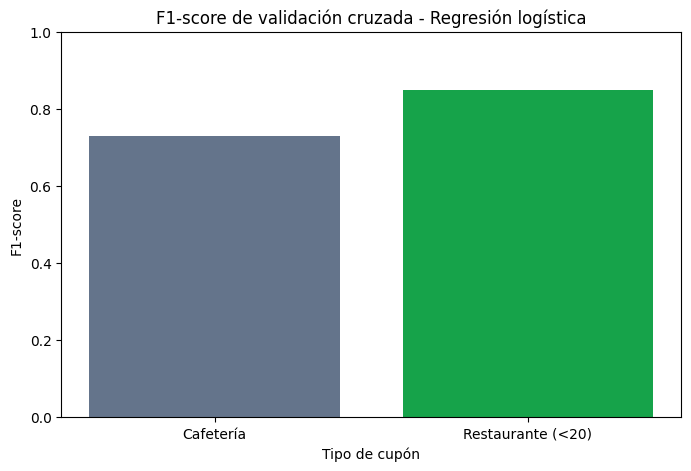

In [35]:
import matplotlib.pyplot as plt

modelos = ['Cafetería', 'Restaurante (<20)']
f1_scores = [
    grid_rl_caf.best_score_,
    grid_rl_res.best_score_
]

plt.figure(figsize=(8, 5))

plt.bar(modelos, f1_scores, color=['#64748B', '#16A34A'])

plt.title('F1-score de validación cruzada - Regresión logística')
plt.xlabel('Tipo de cupón')
plt.ylabel('F1-score')
plt.ylim(0, 1)

plt.show()

### 3.10. Evaluación del modelo de regresión logística — Restaurante(<20) sin SMOTE

Se evalúa el modelo seleccionado mediante validación cruzada sobre el conjunto de prueba de Restaurante(<20).

Se calculan accuracy, precision, recall y F1-score. Asimismo, se obtiene la matriz de confusión para analizar los errores de clasificación.

Debido al desbalance observado en la variable objetivo, se prestará especial atención a la capacidad del modelo para identificar tanto las aceptaciones como los rechazos, evitando interpretar su desempeño únicamente a partir de la exactitud global.

Estos resultados servirán como referencia para evaluar posteriormente el efecto de SMOTE.

In [36]:
# Predicciones - Restaurante (<20)
y_pred_res = grid_rl_res.predict(X_test_res)

print("Accuracy:", accuracy_score(y_test_res, y_pred_res))
print("Precision:", precision_score(y_test_res, y_pred_res))
print("Recall:", recall_score(y_test_res, y_pred_res))
print("F1-score:", f1_score(y_test_res, y_pred_res))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_res, y_pred_res))

print("\nReporte de clasificación:")
print(classification_report(y_test_res, y_pred_res))

Accuracy: 0.7689530685920578
Precision: 0.7882096069868996
Recall: 0.9209183673469388
F1-score: 0.8494117647058823

Matriz de confusión:
[[ 65  97]
 [ 31 361]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.68      0.40      0.50       162
           1       0.79      0.92      0.85       392

    accuracy                           0.77       554
   macro avg       0.73      0.66      0.68       554
weighted avg       0.76      0.77      0.75       554



### 3.11. Análisis de resultados — Regresión logística para Restaurante(<20)

El modelo obtuvo un accuracy de 0,7690, precision de 0,7882, recall de aceptación de 0,9209 y F1-score de 0,8494 sobre prueba.

La matriz de confusión muestra 65 rechazos y 361 aceptaciones correctamente identificados, con 97 falsos positivos y 31 falsos negativos.

Aunque reconoce el 92,09 % de las aceptaciones, solamente identifica el 40,12 % de los rechazos. Esto muestra que el buen F1-score de la clase positiva no implica un desempeño equivalente en ambas clases.

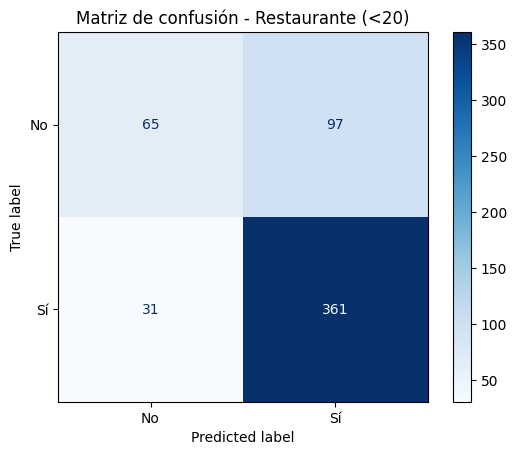

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz_res = confusion_matrix(y_test_res, y_pred_res)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_res,
    display_labels=['No', 'Sí']
)

disp.plot(cmap='Blues')

plt.title('Matriz de confusión - Restaurante (<20)')
plt.show()

,Modelo,Accuracy,Precision,Recall,F1-score
0,Cafetería,0.701,0.6916,0.7229,0.7069
1,Restaurante(<20),0.769,0.7882,0.9209,0.8494


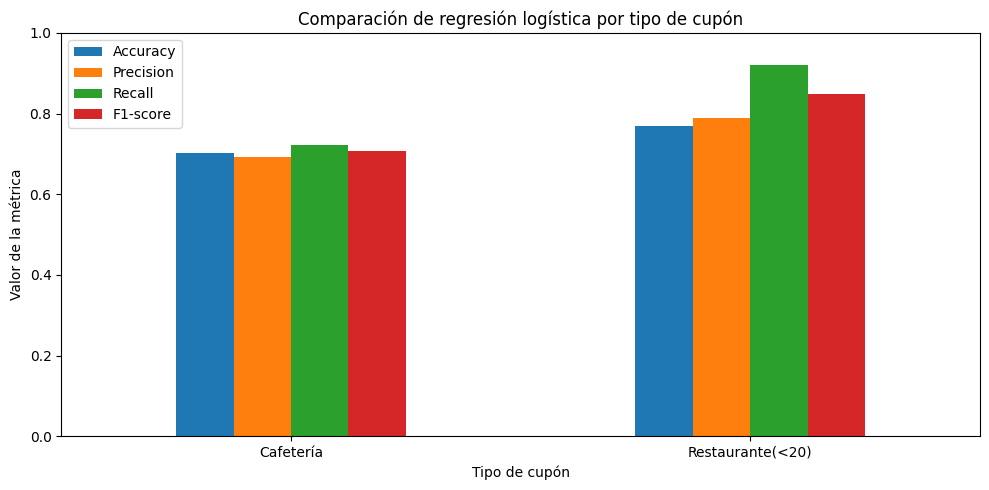

In [38]:
comparacion_rl = pd.DataFrame([
    {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_real, y_pred),
        'Precision': precision_score(y_real, y_pred),
        'Recall': recall_score(y_real, y_pred),
        'F1-score': f1_score(y_real, y_pred)
    }
    for nombre, y_real, y_pred in [
        ('Cafetería', y_test_caf, y_pred_caf),
        ('Restaurante(<20)', y_test_res, y_pred_res)
    ]
])

display(comparacion_rl.round(4))

comparacion_rl.set_index('Modelo').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Comparación de regresión logística por tipo de cupón')
plt.ylabel('Valor de la métrica')
plt.xlabel('Tipo de cupón')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.12. Análisis gráfico de los modelos de regresión logística

La comparación muestra valores superiores de accuracy, precision, recall y F1-score de aceptación para Restaurante(<20).

Sin embargo, su matriz de confusión registra 97 rechazos clasificados como aceptaciones. Por tanto, la comparación entre cupones debe considerar sus diferentes distribuciones de clases y no limitarse al F1-score positivo.

### 3.13. Tratamiento del desbalance de clases mediante SMOTE

En Restaurante(<20), la clase minoritaria corresponde a los rechazos. La regresión logística sin balanceo obtuvo un recall de 0,4012 para esta clase, frente a 0,9209 para las aceptaciones.

Se experimenta con SMOTE para evaluar si mejora la identificación de los rechazos. El balanceo se incorpora dentro del pipeline de `imblearn`, por lo que se aplica únicamente al entrenamiento de cada partición.

Como las variables categóricas se codifican mediante OneHotEncoder, SMOTE convencional puede generar valores intermedios que no correspondan a categorías originales. Esta limitación se tendrá en cuenta al interpretar el experimento.

In [39]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

### 3.14. Construcción del pipeline con SMOTE

Se construye un pipeline que integra el preprocesamiento de los datos, el balanceo mediante SMOTE y el modelo de regresión logística.

SMOTE genera observaciones sintéticas de la clase minoritaria a partir de ejemplos existentes. Su aplicación dentro del pipeline permite realizar el balanceo exclusivamente sobre los datos de entrenamiento de cada partición de validación cruzada, evitando la fuga de información hacia los datos de validación o prueba.

El modelo resultante se comparará con la regresión logística entrenada sin balanceo, prestando especial atención al F1-score y al recall de la clase minoritaria.

Como las variables categóricas fueron transformadas mediante OneHotEncoder, se reconoce que SMOTE convencional puede generar valores intermedios entre categorías codificadas. Esta limitación se tendrá en cuenta al interpretar los resultados.

In [40]:
pipeline_rl_smote = ImbPipeline(steps=[
    ('preprocesador', clone(preprocesador)),
    ('smote', SMOTE(random_state=1)),
    ('modelo', LogisticRegression(
        max_iter=1000,
        random_state=1,
        n_jobs=1
    ))
])

pipeline_rl_smote

,steps,"[('preprocesador', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### 3.15. Selección de hiperparámetros con SMOTE

Se realiza una búsqueda de hiperparámetros para el modelo de regresión logística con SMOTE, utilizando GridSearchCV y validación cruzada estratificada de 10 particiones.

Se mantienen las combinaciones de hiperparámetros exploradas en el modelo sin balanceo, con el fin de facilitar la comparación entre ambos procedimientos.

SMOTE se encuentra integrado dentro del pipeline para generar observaciones sintéticas únicamente a partir de los datos de entrenamiento correspondientes a cada partición.

La selección de hiperparámetros se realizará utilizando el F1-score de la clase positiva. Posteriormente se evaluarán también el F1-score macro y el recall de la clase minoritaria, para determinar si el balanceo mejora la identificación de los rechazos.

In [41]:
grid_rl_res_smote = GridSearchCV(
    estimator=pipeline_rl_smote,
    param_grid=param_grid,
    cv=kfold,
    scoring='f1',
    n_jobs=-2
)

grid_rl_res_smote

,estimator,Pipeline(step...om_state=1))])
,param_grid,"[{'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', ...]}, {'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear']}]"
,scoring,'f1'
,n_jobs,-2
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [42]:
grid_rl_res_smote.fit(X_train_res, y_train_res)

,estimator,Pipeline(step...om_state=1))])
,param_grid,"[{'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', ...]}, {'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear']}]"
,scoring,'f1'
,n_jobs,-2
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [43]:
print("Mejores hiperparámetros con SMOTE:")
print(grid_rl_res_smote.best_params_)

print("\nMejor F1-score de validación cruzada:")
print(grid_rl_res_smote.best_score_)

Mejores hiperparámetros con SMOTE:
{'modelo__C': 0.1, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}

Mejor F1-score de validación cruzada:
0.7974785453024217


### 3.16. Resultados de la búsqueda de hiperparámetros con SMOTE

La búsqueda seleccionó regularización L1, C=0.1 y el solver `liblinear`, con un F1-score promedio de 0,7972 en validación cruzada.

Este resultado es inferior al 0,8494 del modelo sin balanceo. Sin embargo, como la selección utiliza el F1-score de aceptación, también es necesario revisar el recall de rechazo para evaluar el efecto sobre la clase minoritaria.

### 3.17. Evaluación del modelo con SMOTE — Restaurante(<20)

Se evalúa el modelo de regresión logística entrenado con SMOTE sobre el conjunto de prueba original, que no fue balanceado ni utilizado durante el entrenamiento.

Se calculan las métricas accuracy, precision, recall y F1-score, junto con el reporte de clasificación y la matriz de confusión.

Esta evaluación permitirá comparar el desempeño del modelo con y sin balanceo, considerando especialmente su capacidad para identificar los rechazos de cupones.

In [44]:
# Predicciones del modelo con SMOTE
y_pred_res_smote = grid_rl_res_smote.predict(X_test_res)

print("Accuracy:", accuracy_score(y_test_res, y_pred_res_smote))
print("Precision:", precision_score(y_test_res, y_pred_res_smote))
print("Recall:", recall_score(y_test_res, y_pred_res_smote))
print("F1-score:", f1_score(y_test_res, y_pred_res_smote))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_res, y_pred_res_smote))

print("\nReporte de clasificación:")
print(classification_report(y_test_res, y_pred_res_smote))

Accuracy: 0.7220216606498195
Precision: 0.8287292817679558
Recall: 0.7653061224489796
F1-score: 0.7957559681697612

Matriz de confusión:
[[100  62]
 [ 92 300]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.52      0.62      0.56       162
           1       0.83      0.77      0.80       392

    accuracy                           0.72       554
   macro avg       0.67      0.69      0.68       554
weighted avg       0.74      0.72      0.73       554



### 3.18. Comparación del desempeño con y sin SMOTE

Se comparan los resultados de los modelos de regresión logística de Restaurante(<20), entrenados con y sin SMOTE, utilizando el mismo conjunto de prueba.

Se consideran tres métricas: el F1-score de la clase positiva, el F1-score macro y el recall de la clase minoritaria.

Esta comparación permite determinar si la mejora en la identificación de rechazos compensa la posible disminución del desempeño en la predicción de aceptaciones.

                Sin SMOTE  Con SMOTE
F1-score (Sí)    0.849412   0.795756
F1-score macro   0.676644   0.680364
Recall (No)      0.401235   0.617284


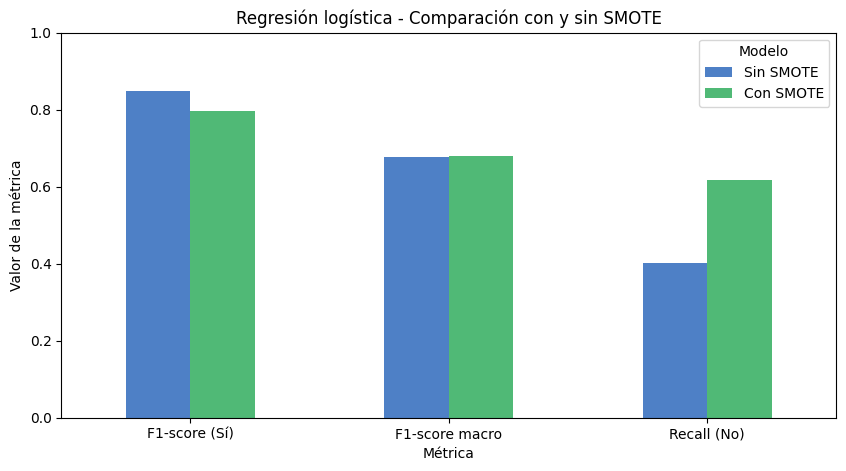

In [45]:
from sklearn.metrics import f1_score, recall_score
import pandas as pd
import matplotlib.pyplot as plt

comparacion_smote = pd.DataFrame({
    'Sin SMOTE': [
        f1_score(y_test_res, y_pred_res),
        f1_score(y_test_res, y_pred_res, average='macro'),
        recall_score(y_test_res, y_pred_res, pos_label=0)
    ],
    'Con SMOTE': [
        f1_score(y_test_res, y_pred_res_smote),
        f1_score(y_test_res, y_pred_res_smote, average='macro'),
        recall_score(y_test_res, y_pred_res_smote, pos_label=0)
    ]
}, index=[
    'F1-score (Sí)',
    'F1-score macro',
    'Recall (No)'
])

print(comparacion_smote)

comparacion_smote.plot(
    kind='bar',
    figsize=(10, 5),
    color=["#4E80C6", "#50B976"]
)

plt.title('Regresión logística - Comparación con y sin SMOTE')
plt.ylabel('Valor de la métrica')
plt.xlabel('Métrica')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Modelo')
plt.show()

### 3.19. Análisis del efecto de SMOTE

El recall de rechazo aumentó de 0,4012 a 0,6173, una mejora de aproximadamente 21,60 puntos porcentuales. Los rechazos correctamente identificados pasaron de 65 a 100.

Al mismo tiempo, el F1-score de aceptación disminuyó de 0,8494 a 0,7926 y el recall de aceptación pasó de 0,9209 a 0,7602.

El F1-score macro prácticamente se mantuvo: pasó de 0,6766 a 0,6772. Por tanto, el aumento en la identificación de rechazos estuvo acompañado de una pérdida en la identificación de aceptaciones.

La recomendación final sobre la conveniencia de aplicar SMOTE se completará en la pregunta 7.4.

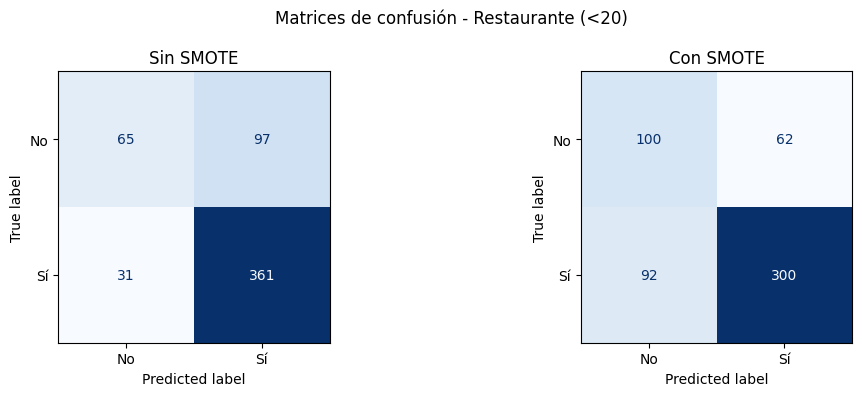

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay

matriz_sin_smote = confusion_matrix(y_test_res, y_pred_res)
matriz_con_smote = confusion_matrix(y_test_res, y_pred_res_smote)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    matriz_sin_smote,
    display_labels=['No', 'Sí']
).plot(ax=axes[0], cmap='Blues', colorbar=False)

axes[0].set_title('Sin SMOTE')

ConfusionMatrixDisplay(
    matriz_con_smote,
    display_labels=['No', 'Sí']
).plot(ax=axes[1], cmap='Blues', colorbar=False)

axes[1].set_title('Con SMOTE')

plt.suptitle('Matrices de confusión - Restaurante (<20)')
plt.tight_layout()
plt.show()

### 4. Modelos de clasificación — Árboles de decisión

#### 4.1. Construcción del pipeline

Se utilizarán árboles de decisión para predecir la aceptación de cupones de Cafetería y Restaurante(<20), siguiendo el procedimiento presentado en la práctica P8.

Este algoritmo construye reglas de clasificación a partir de las características de las observaciones, buscando particiones que permitan distinguir entre las clases de aceptación y rechazo.

Se integra el árbol con el preprocesador definido anteriormente mediante un pipeline. Posteriormente, se realizará una búsqueda de hiperparámetros para controlar la complejidad del modelo y mejorar su capacidad de generalización.

In [47]:
from sklearn.tree import DecisionTreeClassifier

pipeline_arbol = Pipeline(steps=[
    ('preprocesador', clone(preprocesador)),
    ('modelo', DecisionTreeClassifier(random_state=1))
])

pipeline_arbol

,steps,"[('preprocesador', ...), ('modelo', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


#### 4.2. Selección de hiperparámetros mediante validación cruzada

Para seleccionar la configuración del árbol de decisión se utiliza GridSearchCV con validación cruzada estratificada de 10 particiones.

Se exploran diferentes valores de profundidad máxima (`max_depth`), número mínimo de muestras por hoja (`min_samples_leaf`) y criterio de partición (`criterion`).

La selección se realizará mediante el F1-score de la clase positiva, manteniendo el mismo criterio utilizado en los modelos de regresión logística.

El objetivo es encontrar una configuración que permita distinguir entre aceptaciones y rechazos, controlando al mismo tiempo la complejidad del árbol.

In [48]:
param_grid_arbol = {
    'modelo__max_depth': [3, 5, 7, 10, 15],
    'modelo__min_samples_leaf': [1, 5, 10, 20],
    'modelo__criterion': ['gini', 'entropy']
}

grid_arbol_caf = GridSearchCV(
    estimator=pipeline_arbol,
    param_grid=param_grid_arbol,
    cv=kfold,
    scoring='f1',
    n_jobs=-2
)

grid_arbol_caf

,estimator,Pipeline(step...om_state=1))])
,param_grid,"{'modelo__criterion': ['gini', 'entropy'], 'modelo__max_depth': [3, 5, ...], 'modelo__min_samples_leaf': [1, 5, ...]}"
,scoring,'f1'
,n_jobs,-2
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


#### 4.3. Entrenamiento del árbol de decisión — Cafetería

Se entrena un árbol de decisión para predecir la aceptación de cupones de Cafetería utilizando el conjunto de entrenamiento.

Mediante GridSearchCV se evalúan 40 combinaciones de hiperparámetros con validación cruzada estratificada de 10 particiones.

La selección se realiza a partir del F1-score promedio de la clase positiva. Las transformaciones de los datos se ejecutan dentro del pipeline, evitando utilizar información del conjunto de prueba durante el entrenamiento.

El conjunto de prueba se mantiene reservado para evaluar posteriormente la capacidad de generalización del mejor árbol y comparar su desempeño con la regresión logística.

In [49]:
# Entrenamiento del árbol de decisión - Cafetería
grid_arbol_caf.fit(X_train_caf, y_train_caf)

,estimator,Pipeline(step...om_state=1))])
,param_grid,"{'modelo__criterion': ['gini', 'entropy'], 'modelo__max_depth': [3, 5, ...], 'modelo__min_samples_leaf': [1, 5, ...]}"
,scoring,'f1'
,n_jobs,-2
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [50]:
print("Mejores hiperparámetros:")
print(grid_arbol_caf.best_params_)

print("\nMejor F1-score de validación cruzada:")
print(grid_arbol_caf.best_score_)

Mejores hiperparámetros:
{'modelo__criterion': 'entropy', 'modelo__max_depth': 7, 'modelo__min_samples_leaf': 1}

Mejor F1-score de validación cruzada:
0.7249636349408002


#### 4.4. Resultados de la búsqueda de hiperparámetros — Cafetería

La búsqueda seleccionó el criterio `entropy`, una profundidad máxima de 7 y un mínimo de una observación por hoja.

Esta configuración obtuvo un F1-score promedio de 0,7250 en validación cruzada, ligeramente inferior al 0,7288 de la regresión logística. La comparación sobre prueba permitirá revisar el comportamiento de ambos modelos con registros reservados.

#### 4.5. Evaluación del árbol de decisión — Cafetería

Una vez seleccionados los mejores hiperparámetros mediante validación cruzada, se evalúa el árbol de decisión utilizando las 798 observaciones del conjunto de prueba de Cafetería.

Se calculan las métricas accuracy, precision, recall y F1-score, junto con la matriz de confusión y el reporte de clasificación.

Los resultados permitirán evaluar la capacidad de generalización del árbol y compararlo con la regresión logística entrenada anteriormente.

In [51]:
# Predicciones del árbol de decisión - Cafetería
y_pred_arbol_caf = grid_arbol_caf.predict(X_test_caf)

print("Accuracy:", accuracy_score(y_test_caf, y_pred_arbol_caf))
print("Precision:", precision_score(y_test_caf, y_pred_arbol_caf))
print("Recall:", recall_score(y_test_caf, y_pred_arbol_caf))
print("F1-score:", f1_score(y_test_caf, y_pred_arbol_caf))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_caf, y_pred_arbol_caf))

print("\nReporte de clasificación:")
print(classification_report(y_test_caf, y_pred_arbol_caf))

Accuracy: 0.6947236180904522
Precision: 0.6850961538461539
Recall: 0.7178841309823678
F1-score: 0.7011070110701108

Matriz de confusión:
[[268 131]
 [112 285]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.71      0.67      0.69       399
           1       0.69      0.72      0.70       397

    accuracy                           0.69       796
   macro avg       0.70      0.69      0.69       796
weighted avg       0.70      0.69      0.69       796



#### 4.6. Análisis de resultados — Árbol de decisión para Cafetería

El árbol obtuvo un accuracy de 0,6947, precision de 0,6851, recall de 0,7179 y F1-score de 0,7011.

La matriz de confusión muestra 268 rechazos y 285 aceptaciones correctamente identificados, junto con 131 falsos positivos y 112 falsos negativos.

El F1-score fue ligeramente inferior al de la regresión logística, que obtuvo 0,7069. En esta evaluación, el árbol no presentó una mejora predictiva frente a ese modelo.

#### 4.7. Visualización de las reglas del árbol de decisión — Cafetería

Se representan las primeras divisiones del árbol para identificar las condiciones utilizadas en la clasificación.

El modelo fue seleccionado con una profundidad máxima de 7. Para facilitar la lectura, la gráfica se limita a profundidad 3, contando la raíz como profundidad 0.

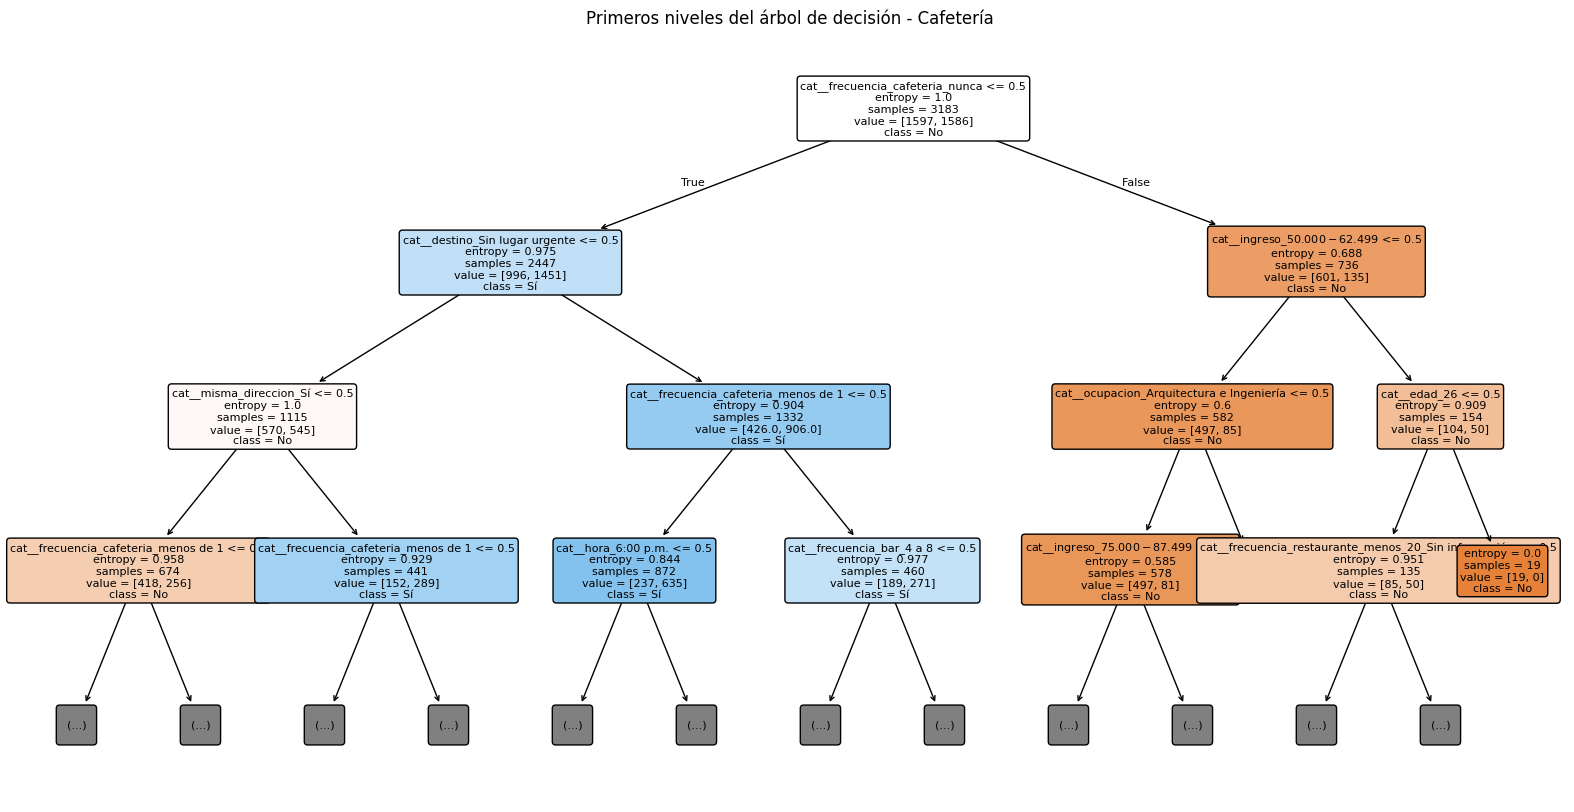

In [52]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Recuperar el mejor pipeline
mejor_arbol_caf = grid_arbol_caf.best_estimator_

# Recuperar el árbol entrenado
arbol_caf = mejor_arbol_caf.named_steps['modelo']

# Recuperar los nombres de variables transformadas
nombres_variables_caf = (
    mejor_arbol_caf.named_steps['preprocesador']
    .get_feature_names_out()
)

plt.figure(figsize=(20, 10))

plot_tree(
    arbol_caf,
    feature_names=nombres_variables_caf,
    class_names=['No', 'Sí'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title('Primeros niveles del árbol de decisión - Cafetería')
plt.show()

#### 4.8. Interpretación de las reglas del árbol de decisión — Cafetería

La primera división utiliza la categoría `frecuencia_cafeteria_nunca`.

Entre los 736 registros de entrenamiento que indican que nunca visitan cafeterías, 135 corresponden a aceptación, aproximadamente el 18,3 %. En el otro grupo se registran 1.451 aceptaciones de 2.447 observaciones, aproximadamente el 59,3 %. Este segundo grupo también incluye las observaciones cuya frecuencia fue registrada como "Sin información".

Las siguientes divisiones incorporan características como el destino y el ingreso. El árbol combina estas condiciones para formar sus reglas, por lo que una sola característica no determina todas las predicciones.

Estas proporciones describen el entrenamiento y representan asociaciones observadas, no efectos causales.

#### 4.9. Importancia de variables — Árbol de decisión para Cafetería

Se analiza la importancia de las variables utilizadas por el árbol de decisión mediante el atributo `feature_importances_`.

Esta medida representa la contribución relativa de cada característica a la reducción de impureza durante la construcción del árbol.

Se visualizan las diez características transformadas con mayor importancia para identificar los factores que más contribuyen a las predicciones del modelo.

Estos resultados permitirán complementar la interpretación de las reglas y analizar cuáles características del conductor y del contexto son más relevantes para la aceptación de cupones.

cat__frecuencia_cafeteria_nunca               0.307828
cat__destino_Sin lugar urgente                0.087389
cat__misma_direccion_Sí                       0.062521
cat__frecuencia_cafeteria_menos de 1          0.060534
cat__vigencia_cupon_2 horas                   0.048998
cat__ingreso_$50.000 - $62.499                0.026784
cat__hora_10:00 p.m.                          0.020191
cat__frecuencia_restaurante_menos_20_4 a 8    0.017828
cat__ocupacion_Ventas y afines                0.017335
cat__hora_6:00 p.m.                           0.016129
dtype: float64


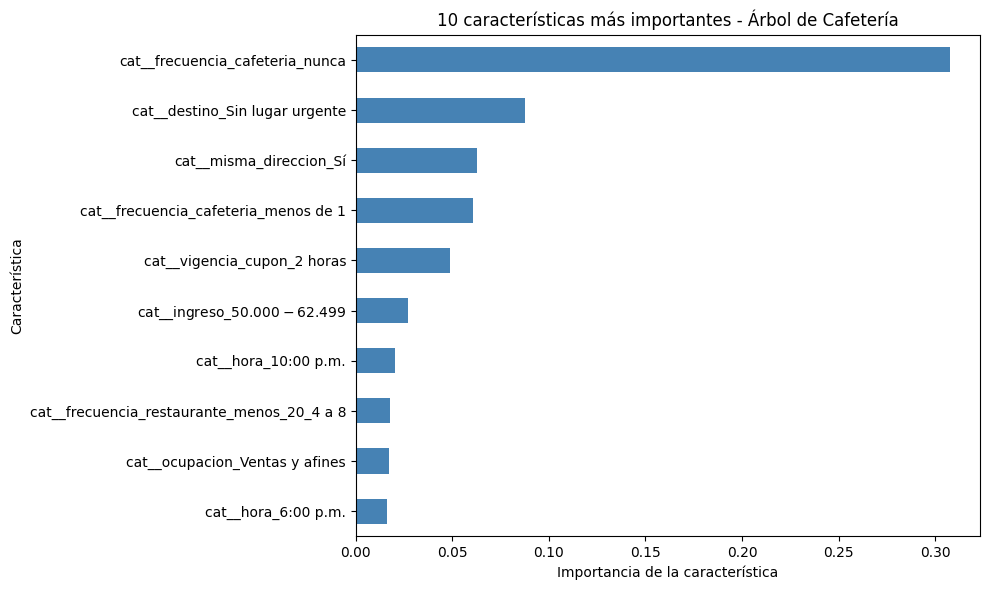

In [53]:
import pandas as pd
import matplotlib.pyplot as plt

# Importancia de las variables del árbol
importancias_caf = pd.Series(
    arbol_caf.feature_importances_,
    index=nombres_variables_caf
)

# Seleccionar las 10 características más importantes
top_importancias_caf = (
    importancias_caf[importancias_caf > 0]
    .sort_values(ascending=False)
    .head(10)
)

print(top_importancias_caf)

# Visualización
plt.figure(figsize=(10, 6))

top_importancias_caf.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('10 características más importantes - Árbol de Cafetería')
plt.xlabel('Importancia de la característica')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

#### 4.10. Análisis de importancia de variables — Cafetería

La categoría `frecuencia_cafeteria_nunca` presenta la mayor importancia en el árbol, con un valor de 0,3078.

Le siguen `destino_Sin lugar urgente` (0,0874), `misma_direccion_Sí` (0,0625), `frecuencia_cafeteria_menos de 1` (0,0605) y `vigencia_cupon_2 horas` (0,0490).

El modelo utiliza información sobre los hábitos de consumo, el recorrido y la vigencia de la oferta. Las importancias corresponden a reducción de impureza y se presentan por categoría codificada; no representan cambios directos en la probabilidad de aceptación.

### 4.11. Árbol de decisión — Restaurante(<20)

Se entrena un árbol de decisión para predecir la aceptación de cupones de Restaurante(<20).

Se utiliza un pipeline con las mismas transformaciones aplicadas al modelo de Cafetería y se realiza una búsqueda de hiperparámetros mediante GridSearchCV y validación cruzada estratificada de 10 particiones.

Se exploran diferentes profundidades máximas, cantidades mínimas de muestras por hoja y criterios de partición. El modelo se selecciona utilizando el F1-score de la clase positiva.

El entrenamiento se realiza inicialmente sin SMOTE, manteniendo la distribución original de las clases. Posteriormente, el modelo se evaluará sobre el conjunto de prueba para comparar su desempeño con los demás algoritmos.

In [54]:
# Búsqueda de hiperparámetros - Árbol de Restaurante (<20)
grid_arbol_res = GridSearchCV(
    estimator=pipeline_arbol,
    param_grid=param_grid_arbol,
    cv=kfold,
    scoring='f1',
    n_jobs=-2
)

# Entrenamiento
grid_arbol_res.fit(X_train_res, y_train_res)

print("Mejores hiperparámetros:")
print(grid_arbol_res.best_params_)

print("\nMejor F1-score de validación cruzada:")
print(grid_arbol_res.best_score_)

Mejores hiperparámetros:
{'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 5}

Mejor F1-score de validación cruzada:
0.8450270114162169


#### 4.12. Resultados de la búsqueda de hiperparámetros — Restaurante(<20)

La búsqueda seleccionó el criterio `gini`, una profundidad máxima de 3 y un mínimo de cinco observaciones por hoja.

El F1-score promedio de validación cruzada fue de 0,8450, ligeramente inferior al 0,8494 de la regresión logística sin balanceo.

La configuración produce un árbol de poca profundidad, lo que facilita revisar sus reglas. Su desempeño debe complementarse con las métricas por clase.

#### 4.13. Evaluación del árbol de decisión — Restaurante(<20)

Se evalúa el árbol de decisión seleccionado mediante validación cruzada utilizando el conjunto de prueba de Restaurante(<20).

Se calculan accuracy, precision, recall y F1-score, junto con la matriz de confusión y el reporte de clasificación.

Dado el desbalance entre las clases de aceptación y rechazo, se analizará especialmente el recall de la clase negativa para determinar si el árbol identifica correctamente los conductores que rechazan los cupones.

Los resultados se compararán posteriormente con los modelos de regresión logística.

In [55]:
# Predicciones del árbol de decisión - Restaurante (<20)
y_pred_arbol_res = grid_arbol_res.predict(X_test_res)

print("Accuracy:", accuracy_score(y_test_res, y_pred_arbol_res))
print("Precision:", precision_score(y_test_res, y_pred_arbol_res))
print("Recall:", recall_score(y_test_res, y_pred_arbol_res))
print("F1-score:", f1_score(y_test_res, y_pred_arbol_res))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_res, y_pred_arbol_res))

print("\nReporte de clasificación:")
print(classification_report(y_test_res, y_pred_arbol_res))

Accuracy: 0.7346570397111913
Precision: 0.7704194260485652
Recall: 0.8903061224489796
F1-score: 0.8260355029585799

Matriz de confusión:
[[ 58 104]
 [ 43 349]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.57      0.36      0.44       162
           1       0.77      0.89      0.83       392

    accuracy                           0.73       554
   macro avg       0.67      0.62      0.63       554
weighted avg       0.71      0.73      0.71       554



#### 4.14. Análisis de resultados — Árbol de decisión para Restaurante(<20)

El árbol obtuvo un accuracy de 0,7347, precision de 0,7704, recall de aceptación de 0,8903 y F1-score de 0,8260.

La matriz de confusión muestra 58 rechazos y 349 aceptaciones correctamente identificados, con 104 falsos positivos y 43 falsos negativos.

El recall de rechazo fue de 0,3580. Por tanto, el modelo reconoce una proporción mucho mayor de aceptaciones que de rechazos.

Frente a la regresión logística sin SMOTE, el árbol obtuvo menores valores de F1-score y recall en ambas clases.

#### 4.15. Visualización del árbol de decisión — Restaurante(<20)

Se representa el árbol completo para revisar las condiciones que utiliza en la clasificación.

El modelo seleccionado tiene profundidad máxima de 3, contando la raíz como profundidad 0. Su tamaño permite visualizar todas las divisiones.

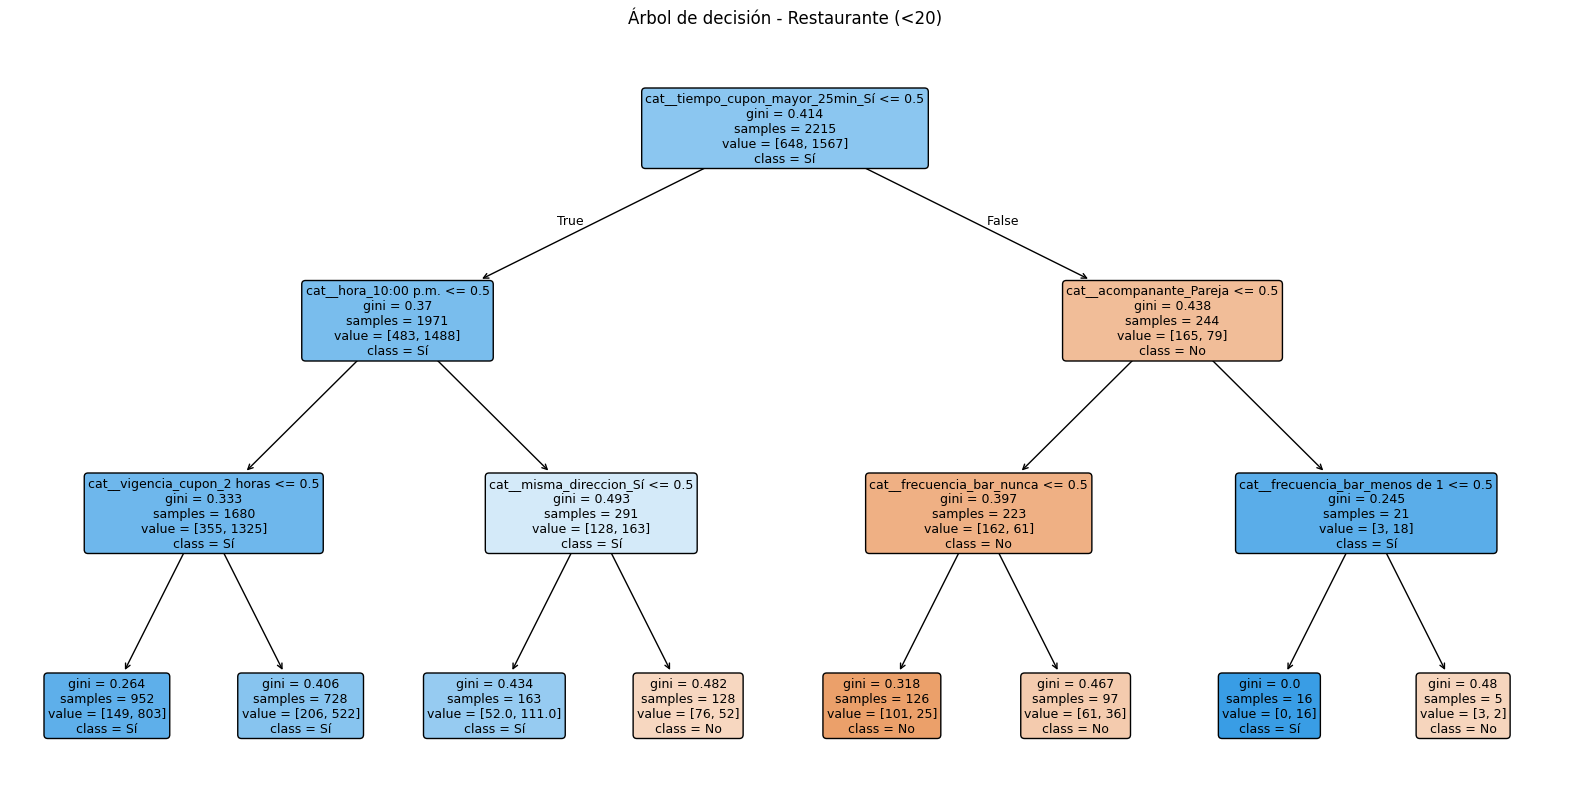

In [56]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Recuperar el mejor pipeline
mejor_arbol_res = grid_arbol_res.best_estimator_

# Recuperar el árbol entrenado
arbol_res = mejor_arbol_res.named_steps['modelo']

# Recuperar los nombres de las características transformadas
nombres_variables_res = (
    mejor_arbol_res.named_steps['preprocesador']
    .get_feature_names_out()
)

plt.figure(figsize=(20, 10))

plot_tree(
    arbol_res,
    feature_names=nombres_variables_res,
    class_names=['No', 'Sí'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Árbol de decisión - Restaurante (<20)')
plt.show()

#### 4.16. Interpretación de las reglas del árbol de decisión — Restaurante(<20)

La primera división identifica si el desplazamiento hacia el establecimiento supera los 25 minutos.

En el grupo donde no se supera ese tiempo, 1.488 de 1.971 registros corresponden a aceptación, aproximadamente el 75,5 %. Cuando el tiempo supera los 25 minutos, se observan 79 aceptaciones de 244 registros, aproximadamente el 32,4 %.

En la siguiente división, el primer grupo utiliza la hora de las 10:00 p. m., mientras que el segundo considera si el acompañante es la pareja.

Estas reglas muestran cómo el árbol combina condiciones del desplazamiento y del contexto. Las proporciones corresponden a entrenamiento y no demuestran que modificar una condición produzca un cambio causal en la aceptación.

#### 4.17. Importancia de variables — Árbol de decisión para Restaurante(<20)

Se calcula la importancia de las características utilizadas por el árbol de decisión de Restaurante(<20), mediante el atributo `feature_importances_`.

Se visualizan las siete características transformadas con mayor importancia para identificar los factores que contribuyen a las decisiones del modelo.

Esta información permitirá comparar las variables relevantes para Restaurante(<20) con las identificadas en Cafetería y analizar las diferencias entre ambos tipos de cupones.

cat__tiempo_cupon_mayor_25min_Sí    0.539117
cat__hora_10:00 p.m.                0.173045
cat__vigencia_cupon_2 horas         0.088104
cat__acompanante_Pareja             0.087304
cat__misma_direccion_Sí             0.072276
cat__frecuencia_bar_nunca           0.021837
cat__frecuencia_bar_menos de 1      0.018317
dtype: float64


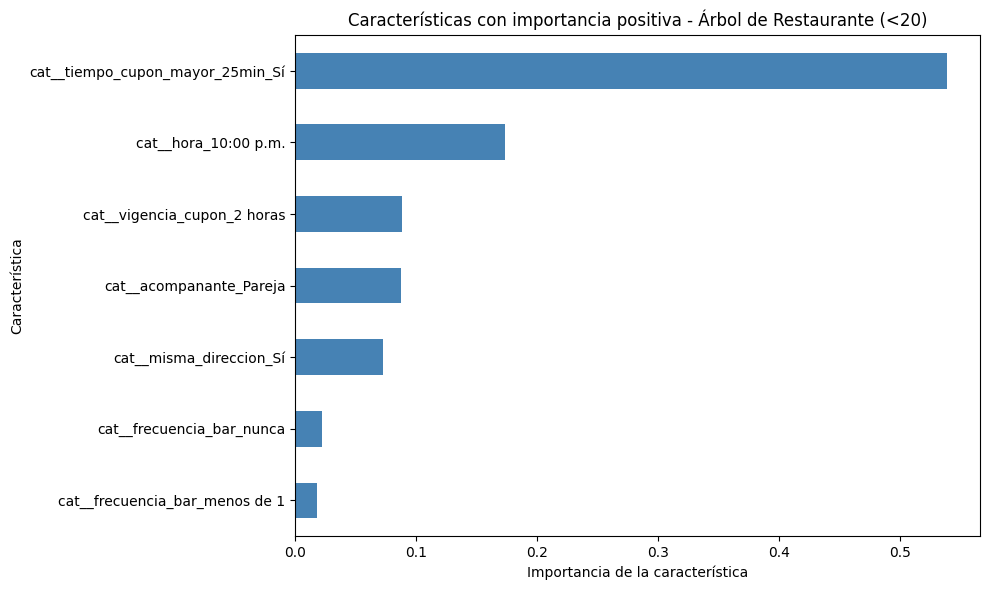

In [57]:
# Importancia de variables - Árbol Restaurante (<20)
importancias_res = pd.Series(
    arbol_res.feature_importances_,
    index=nombres_variables_res
)

top_importancias_res = (
    importancias_res[importancias_res > 0]
    .sort_values(ascending=False)
    .head(10)
)

print(top_importancias_res)

plt.figure(figsize=(10, 6))

top_importancias_res.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('Características con importancia positiva - Árbol de Restaurante (<20)')
plt.xlabel('Importancia de la característica')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

#### 4.18. Análisis de importancia de variables — Restaurante(<20)

La característica `tiempo_cupon_mayor_25min_Sí` concentra la mayor importancia del árbol, con un valor de 0,5391.

Le siguen `hora_10:00 p.m.` (0,1730), `vigencia_cupon_2 horas` (0,0881), `acompanante_Pareja` (0,0873) y `misma_direccion_Sí` (0,0723).

A diferencia del árbol de Cafetería, donde destaca la frecuencia de visitas, en este modelo tiene mayor peso el tiempo de desplazamiento. Las importancias describen el uso de las características dentro del árbol y no deben interpretarse como efectos causales.

### 5. Modelos de clasificación — Random Forest

#### 5.1. Construcción del pipeline

Se desarrollarán dos modelos de clasificación mediante Random Forest: uno para los cupones de Cafetería y otro para los cupones de Restaurante(<20).

Random Forest es un algoritmo de ensamble que combina múltiples árboles de decisión. Su objetivo es obtener predicciones más robustas al agregar las decisiones de distintos árboles.

Para implementar los modelos, se utilizará `RandomForestClassifier` dentro de un pipeline que incorpora el preprocesamiento definido anteriormente. De esta manera, la imputación y la codificación de características se realizarán dentro de cada partición de entrenamiento durante la validación cruzada.

Posteriormente, se utilizará `GridSearchCV` para explorar el número de árboles (`n_estimators`), la profundidad máxima (`max_depth`) y el número mínimo de muestras por hoja (`min_samples_leaf`).

In [58]:
from sklearn.ensemble import RandomForestClassifier

pipeline_rf = Pipeline(steps=[
    ('preprocesador', clone(preprocesador)),
    ('modelo', RandomForestClassifier(
        random_state=1,
        n_jobs=1
    ))
])

pipeline_rf

,steps,"[('preprocesador', ...), ('modelo', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [59]:
print("Cafetería:", X_train_caf.shape)
print("Restaurante:", X_train_res.shape)

print("Variables numéricas:", len(numericas_features))
print("Variables categóricas:", len(categoricas_features))

print("Valores faltantes en y_train_caf:",
      y_train_caf.isna().sum())

print("Valores faltantes en y_train_res:",
      y_train_res.isna().sum())

Cafetería: (3183, 21)
Restaurante: (2215, 21)
Variables numéricas: 1
Variables categóricas: 20
Valores faltantes en y_train_caf: 0
Valores faltantes en y_train_res: 0


#### 5.2. Búsqueda de hiperparámetros — Random Forest para Cafetería

Para seleccionar la mejor configuración del modelo Random Forest correspondiente a los cupones de Cafetería, se utiliza `GridSearchCV` con validación cruzada estratificada de diez particiones.

Se exploran tres hiperparámetros: el número de árboles (`n_estimators`), la profundidad máxima (`max_depth`) y el número mínimo de muestras por hoja (`min_samples_leaf`).

Se utiliza el F1-score de la clase positiva como métrica de selección, buscando equilibrar la precisión y el recall en la predicción de aceptación del cupón.

El proceso se desarrolla dentro de un pipeline que incluye las transformaciones de preprocesamiento, con el fin de evitar utilizar información del conjunto de prueba durante el ajuste del modelo.

In [60]:
# Hiperparámetros de Random Forest
param_grid_rf = {
    'modelo__n_estimators': [50, 100, 200],
    'modelo__max_depth': [5, 10, 15],
    'modelo__min_samples_leaf': [1, 5, 10]
}

# Búsqueda de hiperparámetros para Cafetería
grid_rf_caf = GridSearchCV(
    pipeline_rf,
    param_grid=param_grid_rf,
    cv=kfold,
    scoring='f1',
    n_jobs=-2
)

# Entrenar el modelo
grid_rf_caf.fit(X_train_caf, y_train_caf)

# Mostrar resultados
print("Mejores hiperparámetros:")
print(grid_rf_caf.best_params_)

print("\nMejor F1-score en validación cruzada:")
print(grid_rf_caf.best_score_)

Mejores hiperparámetros:
{'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}

Mejor F1-score en validación cruzada:
0.7706662628536456


#### 5.3. Resultados de la búsqueda de hiperparámetros — Cafetería

La búsqueda seleccionó 200 árboles, profundidad máxima de 15 y un mínimo de una observación por hoja.

Esta configuración obtuvo un F1-score promedio de 0,7697 en validación cruzada. Fue la mejor combinación dentro de los valores explorados.

A continuación, se evalúa sobre el conjunto de prueba para comparar sus resultados con los otros algoritmos.

#### 5.4. Evaluación de Random Forest — Cafetería

Se evalúa el mejor modelo de Random Forest sobre el conjunto de prueba de Cafetería.

Para medir su desempeño, se calculan accuracy, precision, recall y F1-score. También se genera la matriz de confusión y el reporte de clasificación, con el propósito de analizar los errores cometidos en las clases de aceptación y rechazo.

Esta evaluación permitirá comparar posteriormente Random Forest con los modelos de regresión logística y árbol de decisión.

In [61]:
# Predicciones sobre el conjunto de prueba
y_pred_rf_caf = grid_rf_caf.predict(X_test_caf)

# Métricas de evaluación
print("Accuracy:", accuracy_score(y_test_caf, y_pred_rf_caf))
print("Precision:", precision_score(y_test_caf, y_pred_rf_caf))
print("Recall:", recall_score(y_test_caf, y_pred_rf_caf))
print("F1-score:", f1_score(y_test_caf, y_pred_rf_caf))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_caf, y_pred_rf_caf))

print("\nReporte de clasificación:")
print(classification_report(y_test_caf, y_pred_rf_caf))

Accuracy: 0.7562814070351759
Precision: 0.7377049180327869
Recall: 0.7934508816120907
F1-score: 0.7645631067961165

Matriz de confusión:
[[287 112]
 [ 82 315]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.78      0.72      0.75       399
           1       0.74      0.79      0.76       397

    accuracy                           0.76       796
   macro avg       0.76      0.76      0.76       796
weighted avg       0.76      0.76      0.76       796



#### 5.5. Análisis de resultados — Random Forest para Cafetería

Random Forest obtuvo un accuracy de 0,7563, precision de 0,7388, recall de aceptación de 0,7909 y F1-score de 0,7640.

La matriz de confusión muestra 288 rechazos y 314 aceptaciones correctamente identificados, con 111 falsos positivos y 83 falsos negativos.

El modelo reconoce el 79,09 % de las aceptaciones y el 72,18 % de los rechazos. Su F1-score de prueba es superior al de regresión logística y al del árbol de decisión en este subconjunto.

El resultado es cercano al F1-score promedio de validación cruzada de 0,7697, aunque esto no garantiza el mismo desempeño en otros datos.

#### 5.6. Visualización de la matriz de confusión — Random Forest para Cafetería

Se presenta gráficamente la matriz de confusión del modelo Random Forest para facilitar la identificación de predicciones correctas y errores de clasificación.

La visualización permite distinguir verdaderos negativos, falsos positivos, falsos negativos y verdaderos positivos, y será utilizada posteriormente en la comparación con los demás algoritmos.

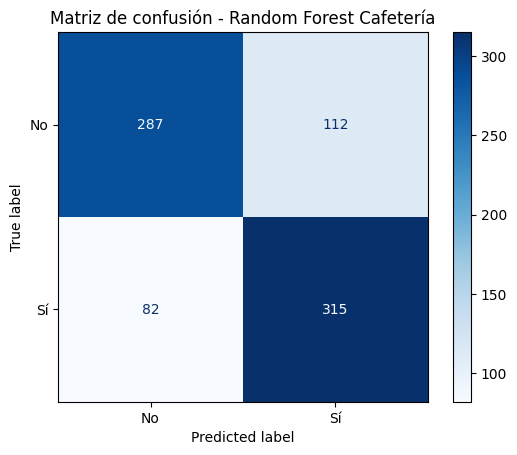

In [62]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_caf,
    y_pred_rf_caf,
    display_labels=['No', 'Sí'],
    cmap='Blues'
)

plt.title('Matriz de confusión - Random Forest Cafetería')
plt.show()

#### 5.7. Búsqueda de hiperparámetros — Random Forest para Restaurante(<20)

Se desarrolla un modelo Random Forest para predecir la aceptación de cupones de Restaurante(<20).

Al igual que en Cafetería, se utiliza un pipeline que incorpora las transformaciones de preprocesamiento y el clasificador `RandomForestClassifier`.

La búsqueda de hiperparámetros se realiza mediante `GridSearchCV`, utilizando validación cruzada estratificada de diez particiones. Se exploran el número de árboles (`n_estimators`), la profundidad máxima (`max_depth`) y el número mínimo de muestras por hoja (`min_samples_leaf`).

Se utiliza el F1-score de la clase positiva como métrica de selección. Posteriormente, el mejor modelo será evaluado en el conjunto de prueba para determinar su capacidad de generalización y analizar su desempeño en ambas clases.

In [63]:
# Búsqueda de hiperparámetros para Restaurante (<20)
grid_rf_res = GridSearchCV(
    pipeline_rf,
    param_grid=param_grid_rf,
    cv=kfold,
    scoring='f1',
    n_jobs=-2
)

# Entrenar el modelo
grid_rf_res.fit(X_train_res, y_train_res)

# Mostrar resultados
print("Mejores hiperparámetros:")
print(grid_rf_res.best_params_)

print("\nMejor F1-score en validación cruzada:")
print(grid_rf_res.best_score_)

Mejores hiperparámetros:
{'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}

Mejor F1-score en validación cruzada:
0.859256155659376


#### 5.8. Resultados de la búsqueda de hiperparámetros — Restaurante(<20)

La búsqueda seleccionó 200 árboles, profundidad máxima de 15 y un mínimo de una observación por hoja.

El mejor F1-score promedio de validación cruzada fue de 0,8585. La configuración coincide con la seleccionada para Cafetería, aunque los modelos se ajustaron de forma independiente.

Debido al desbalance de Restaurante(<20), la evaluación también debe considerar la identificación de los rechazos.

#### 5.9. Evaluación de Random Forest — Restaurante(<20)

Se evalúa el mejor modelo de Random Forest para Restaurante(<20) sobre el conjunto de prueba.

Se calculan accuracy, precision, recall y F1-score, junto con la matriz de confusión y el reporte de clasificación.

Además del desempeño de la clase positiva, se analiza el recall y el F1-score de los rechazos, debido al desbalance presente en este subconjunto.

Estos resultados permitirán comparar Random Forest con regresión logística y árboles de decisión y evaluar si presenta una mejora en la clasificación de ambas clases.

In [64]:
# Predicciones de Random Forest para Restaurante (<20)
y_pred_rf_res = grid_rf_res.predict(X_test_res)

# Métricas de evaluación
print("Accuracy:", accuracy_score(y_test_res, y_pred_rf_res))
print("Precision:", precision_score(y_test_res, y_pred_rf_res))
print("Recall:", recall_score(y_test_res, y_pred_rf_res))
print("F1-score:", f1_score(y_test_res, y_pred_rf_res))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_res, y_pred_rf_res))

print("\nReporte de clasificación:")
print(classification_report(y_test_res, y_pred_rf_res))

Accuracy: 0.7617328519855595
Precision: 0.7838427947598253
Recall: 0.9158163265306123
F1-score: 0.8447058823529412

Matriz de confusión:
[[ 63  99]
 [ 33 359]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.66      0.39      0.49       162
           1       0.78      0.92      0.84       392

    accuracy                           0.76       554
   macro avg       0.72      0.65      0.67       554
weighted avg       0.75      0.76      0.74       554



#### 5.10. Análisis de resultados — Random Forest para Restaurante(<20)

Random Forest obtuvo un accuracy de 0,7653, precision de 0,7860, recall de aceptación de 0,9184 y F1-score de 0,8471.

La matriz de confusión muestra 64 rechazos y 360 aceptaciones correctamente identificados, con 98 falsos positivos y 32 falsos negativos.

El recall de rechazo fue de 0,3951 y el F1-score macro de 0,6716. Esto muestra que el modelo mantiene una mayor capacidad para reconocer aceptaciones que rechazos.

Aunque obtuvo el mayor F1-score de validación cruzada, su F1-score de prueba fue ligeramente inferior al de la regresión logística, que alcanzó 0,8494. Esta diferencia se tendrá en cuenta al explicar la selección final.

#### 5.11. Visualización de la matriz de confusión — Random Forest para Restaurante(<20)

Se representa gráficamente la matriz de confusión del modelo Random Forest para Restaurante(<20).

La visualización permite identificar las predicciones correctas y los errores de clasificación, especialmente los falsos positivos correspondientes a conductores que rechazaron el cupón, pero fueron clasificados como posibles aceptantes.

Esta información será utilizada en la comparación de los modelos y en el análisis del desbalance de clases.

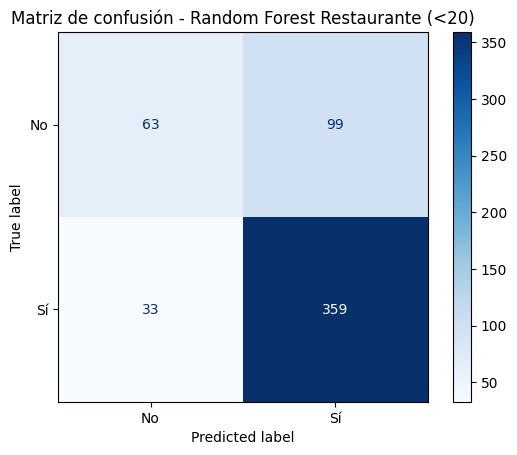

In [65]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_res,
    y_pred_rf_res,
    display_labels=['No', 'Sí'],
    cmap='Blues'
)

plt.title('Matriz de confusión - Random Forest Restaurante (<20)')
plt.show()

#### 5.12. Importancia de características — Random Forest para Cafetería

Para identificar las características más relevantes en la predicción de aceptación de cupones de Cafetería, se calcula la importancia de las variables del mejor modelo Random Forest.

Se utiliza el atributo `feature_importances_`, que mide la contribución relativa de cada característica a la reducción de impureza de los árboles del ensamble.

Posteriormente, se representan gráficamente las diez características transformadas con mayor importancia.

Este análisis permitirá comparar los patrones identificados por Random Forest con los obtenidos previamente mediante árboles de decisión. Las importancias no deben interpretarse como relaciones causales.

cat__frecuencia_cafeteria_nunca         0.115279
cat__vigencia_cupon_2 horas             0.037225
cat__destino_Sin lugar urgente          0.029167
num__temperatura                        0.026159
cat__tiempo_cupon_mayor_15min_Sí        0.025626
cat__hora_6:00 p.m.                     0.021046
cat__frecuencia_cafeteria_menos de 1    0.020747
cat__frecuencia_cafeteria_4 a 8         0.020453
cat__acompanante_Solo                   0.019662
cat__genero_Masculino                   0.018633
dtype: float64


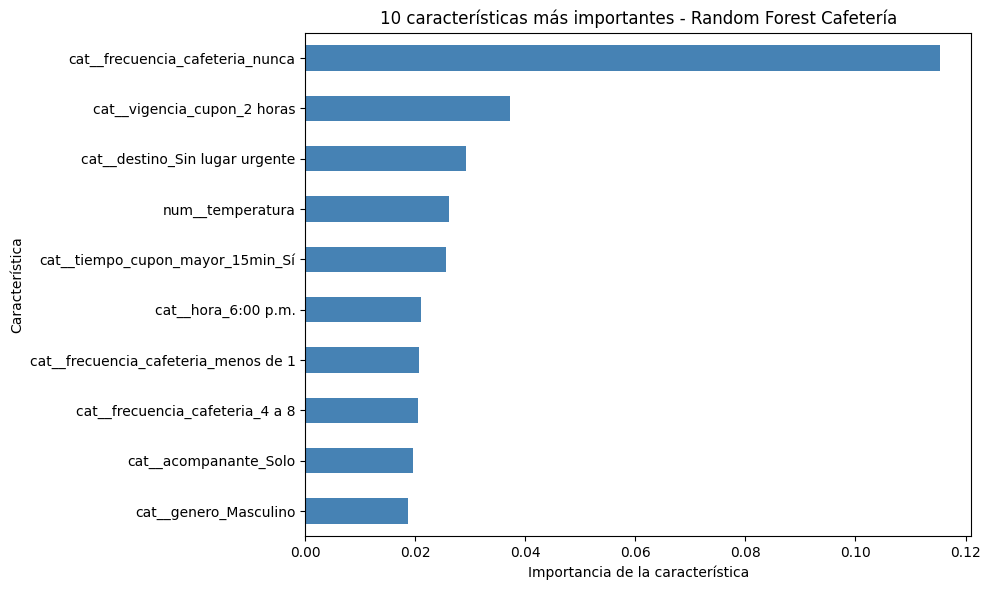

In [66]:
# Recuperar el mejor modelo de Cafetería
mejor_rf_caf = grid_rf_caf.best_estimator_

# Obtener el clasificador Random Forest
modelo_rf_caf = mejor_rf_caf.named_steps['modelo']

# Obtener nombres de las características transformadas
nombres_rf_caf = (
    mejor_rf_caf.named_steps['preprocesador']
    .get_feature_names_out()
)

# Calcular importancia de características
importancias_rf_caf = pd.Series(
    modelo_rf_caf.feature_importances_,
    index=nombres_rf_caf
)

# Seleccionar las diez más importantes
top_rf_caf = importancias_rf_caf.sort_values(
    ascending=False
).head(10)

print(top_rf_caf)

# Graficar
plt.figure(figsize=(10, 6))

top_rf_caf.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('10 características más importantes - Random Forest Cafetería')
plt.xlabel('Importancia de la característica')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

#### 5.13. Análisis de importancia de características — Random Forest para Cafetería

La categoría `frecuencia_cafeteria_nunca` presenta la mayor importancia individual, con un valor de 0,1154.

Le siguen `vigencia_cupon_2 horas` (0,0371), `destino_Sin lugar urgente` (0,0292), `temperatura` (0,0261) y `tiempo_cupon_mayor_15min_Sí` (0,0255).

Al igual que en el árbol de decisión, la categoría correspondiente a quienes nunca visitan cafeterías ocupa el primer lugar. En Random Forest, la importancia se distribuye entre más características del ensamble.

Estos valores corresponden a categorías transformadas. No indican por sí solos si una característica aumenta o disminuye la aceptación.

#### 5.14. Importancia de características — Random Forest para Restaurante(<20)

Se calcula la importancia de las características del mejor modelo Random Forest correspondiente a Restaurante(<20).

Para ello, se utiliza el atributo `feature_importances_` del clasificador y se recuperan los nombres de las características generadas durante el preprocesamiento.

Posteriormente, se representan gráficamente las diez características transformadas con mayor importancia.

Este análisis permitirá identificar los factores predictivos más relevantes para Restaurante(<20) y compararlos con los encontrados en Cafetería y en los modelos de árboles de decisión.

cat__vigencia_cupon_2 horas         0.050874
cat__destino_Sin lugar urgente      0.032645
cat__tiempo_cupon_mayor_25min_Sí    0.032007
num__temperatura                    0.028510
cat__clima_Soleado                  0.028026
cat__hora_10:00 p.m.                0.027709
cat__hora_6:00 p.m.                 0.023580
cat__tiempo_cupon_mayor_15min_Sí    0.021330
cat__acompanante_Solo               0.019864
cat__frecuencia_bar_nunca           0.019343
dtype: float64


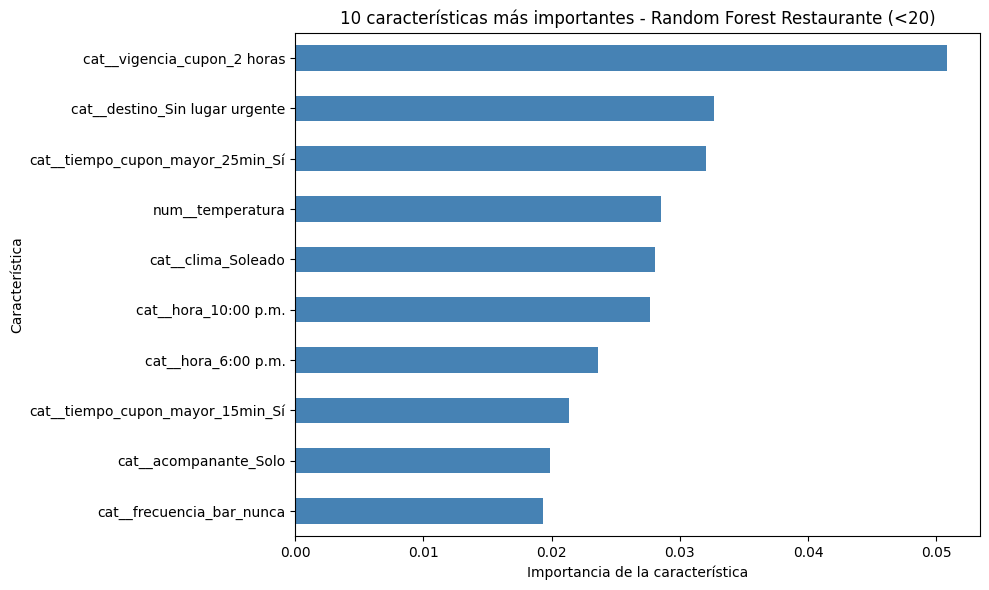

In [67]:
# Recuperar el mejor modelo de Restaurante (<20)
mejor_rf_res = grid_rf_res.best_estimator_

# Obtener el clasificador Random Forest
modelo_rf_res = mejor_rf_res.named_steps['modelo']

# Obtener los nombres de las características transformadas
nombres_rf_res = (
    mejor_rf_res.named_steps['preprocesador']
    .get_feature_names_out()
)

# Calcular importancia de características
importancias_rf_res = pd.Series(
    modelo_rf_res.feature_importances_,
    index=nombres_rf_res
)

# Seleccionar las diez características más importantes
top_rf_res = importancias_rf_res.sort_values(
    ascending=False
).head(10)

print(top_rf_res)

# Graficar
plt.figure(figsize=(10, 6))

top_rf_res.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('10 características más importantes - Random Forest Restaurante (<20)')
plt.xlabel('Importancia de la característica')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

#### 5.15. Análisis de importancia de características — Random Forest para Restaurante(<20)

La característica individual con mayor importancia es `vigencia_cupon_2 horas`, con un valor de 0,0511.

Le siguen `destino_Sin lugar urgente` (0,0326), `tiempo_cupon_mayor_25min_Sí` (0,0319), `temperatura` (0,0285), `clima_Soleado` (0,0278) y `hora_10:00 p.m.` (0,0277).

El modelo utiliza información sobre la oferta y el contexto del desplazamiento. Sin embargo, una misma variable original puede estar representada por varias categorías, por lo que este orden no equivale necesariamente al orden de importancia de las variables completas.

#### 5.16. Importancia agrupada por variable original

Para complementar las gráficas anteriores, se suman las importancias de las categorías que pertenecen a una misma variable original.

Esto permite comparar variables completas, como ocupación, ingreso o frecuencia de visitas, conservando la importancia calculada por Random Forest.

Cafetería:


,Importancia
Variable,
frecuencia_cafeteria,0.1705
ocupacion,0.1271
ingreso,0.0822
edad,0.0668
educacion,0.0521
hora,0.0509
frecuencia_bar,0.0471
frecuencia_restaurante_20_a_50,0.0439
frecuencia_comida_para_llevar,0.0431


Restaurante(<20):


,Importancia
Variable,
ocupacion,0.1273
ingreso,0.0876
hora,0.0775
edad,0.0700
frecuencia_cafeteria,0.0585
educacion,0.0573
vigencia_cupon,0.0509
frecuencia_bar,0.0488
frecuencia_comida_para_llevar,0.0470


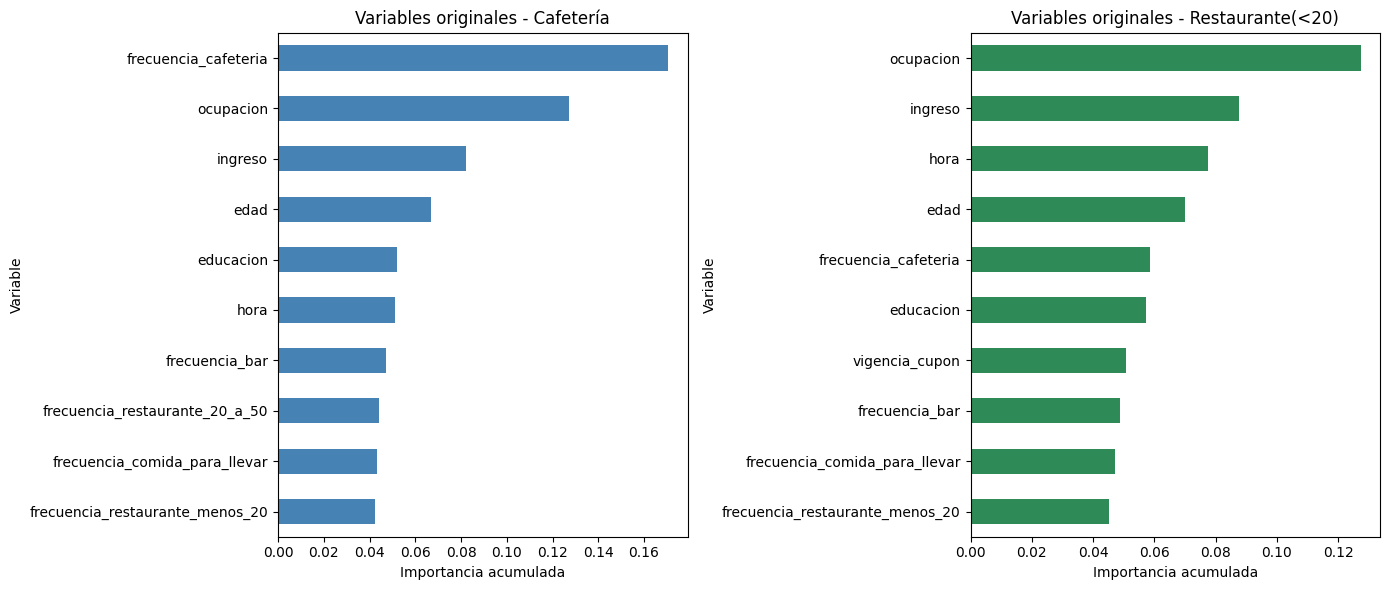

In [68]:
def obtener_importancias_agrupadas(grid):
    pipeline = grid.best_estimator_
    preprocesador_modelo = pipeline.named_steps['preprocesador']
    modelo = pipeline.named_steps['modelo']

    codificador = (
        preprocesador_modelo
        .named_transformers_['cat']
        .named_steps['onehot']
    )

    variables_originales = list(numericas_features)

    for i, columna in enumerate(categoricas_features):
        cantidad = len(codificador.categories_[i])

        if (
            codificador.drop_idx_ is not None
            and codificador.drop_idx_[i] is not None
        ):
            cantidad -= 1

        variables_originales.extend([columna] * cantidad)

    tabla = pd.DataFrame({
        'Variable': variables_originales,
        'Importancia': modelo.feature_importances_
    })

    return (
        tabla.groupby('Variable')['Importancia']
        .sum()
        .sort_values(ascending=False)
    )


importancias_agrupadas_caf = obtener_importancias_agrupadas(grid_rf_caf)
importancias_agrupadas_res = obtener_importancias_agrupadas(grid_rf_res)

print("Cafetería:")
display(importancias_agrupadas_caf.to_frame().round(4))

print("Restaurante(<20):")
display(importancias_agrupadas_res.to_frame().round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

importancias_agrupadas_caf.head(10).sort_values().plot(
    kind='barh',
    ax=axes[0],
    color='steelblue'
)

importancias_agrupadas_res.head(10).sort_values().plot(
    kind='barh',
    ax=axes[1],
    color='seagreen'
)

axes[0].set_title('Variables originales - Cafetería')
axes[1].set_title('Variables originales - Restaurante(<20)')

for ax in axes:
    ax.set_xlabel('Importancia acumulada')
    ax.set_ylabel('Variable')

plt.tight_layout()
plt.show()

En Cafetería, las mayores importancias agrupadas corresponden a frecuencia de visitas a cafeterías (0,1705), ocupación (0,1272), ingreso (0,0823) y edad (0,0665).

En Restaurante(<20), destacan ocupación (0,1274), ingreso (0,0875), hora (0,0777) y edad (0,0699).

Este resultado complementa el análisis por categoría. Por ejemplo, una variable como ocupación distribuye su importancia entre varias columnas generadas por OneHotEncoder.

Las importancias por reducción de impureza pueden favorecer variables con muchas categorías. Agruparlas no elimina esa limitación. Además, estos valores no establecen causalidad ni muestran la dirección de la relación con la aceptación.

### 6. Comparación de los modelos de clasificación

#### 6.1. Criterio de comparación

Se comparan regresión logística, árbol de decisión y Random Forest para cada tipo de cupón. En Restaurante(<20) también se incluye la regresión logística con SMOTE.

La selección utiliza el F1-score promedio de validación cruzada sobre entrenamiento. Se reporta su desviación estándar para describir la variación entre folds.

Las métricas de prueba permiten evaluar los modelos sobre la misma partición de cada cupón. Se incluyen accuracy, precision, recall y F1-score de aceptación, además del F1-score macro y el recall de rechazo.

In [69]:
modelos_verificar = {
    'Logística Cafetería': (grid_rl_caf, X_train_caf.columns),
    'Árbol Cafetería': (grid_arbol_caf, X_train_caf.columns),
    'Random Forest Cafetería': (grid_rf_caf, X_train_caf.columns),
    'Logística Restaurante': (grid_rl_res, X_train_res.columns),
    'Árbol Restaurante': (grid_arbol_res, X_train_res.columns),
    'Random Forest Restaurante': (grid_rf_res, X_train_res.columns),
    'Logística + SMOTE Restaurante': (
        grid_rl_res_smote,
        X_train_res.columns
    )
}

for nombre, (grid, columnas_esperadas) in modelos_verificar.items():
    columnas_modelo = grid.best_estimator_.feature_names_in_

    assert list(columnas_modelo) == list(columnas_esperadas)

    print(nombre, ":", len(columnas_modelo), "variables verificadas")

Logística Cafetería : 21 variables verificadas
Árbol Cafetería : 21 variables verificadas
Random Forest Cafetería : 21 variables verificadas
Logística Restaurante : 21 variables verificadas
Árbol Restaurante : 21 variables verificadas
Random Forest Restaurante : 21 variables verificadas
Logística + SMOTE Restaurante : 21 variables verificadas


#### 6.2. Tabla comparativa de los modelos

Los siete modelos utilizan 21 variables predictoras originales: una numérica y veinte categóricas.

Precision, recall y F1-score se refieren a la clase "Sí". El F1-score macro promedia el resultado de ambas clases y el recall de "No" permite revisar la identificación de rechazos.

Las columnas de validación cruzada corresponden al criterio de selección. Las demás métricas se calculan sobre el conjunto de prueba de cada cupón.

In [70]:
modelos_caf = {
    'Regresión logística': grid_rl_caf,
    'Árbol de decisión': grid_arbol_caf,
    'Random Forest': grid_rf_caf
}

modelos_res = {
    'Regresión logística': grid_rl_res,
    'Árbol de decisión': grid_arbol_res,
    'Random Forest': grid_rf_res,
    'Regresión logística + SMOTE': grid_rl_res_smote
}


def construir_tabla(modelos, X_test, y_test):
    resultados = []

    for nombre, grid in modelos.items():
        predicciones = grid.predict(X_test)

        resultados.append({
            'Modelo': nombre,
            'F1 CV': grid.best_score_,
            'Desv. F1 CV': grid.cv_results_['std_test_score'][
                grid.best_index_
            ],
            'Accuracy': accuracy_score(y_test, predicciones),
            'Precision': precision_score(y_test, predicciones),
            'Recall': recall_score(y_test, predicciones),
            'F1-score': f1_score(y_test, predicciones),
            'F1 macro': f1_score(
                y_test,
                predicciones,
                average='macro'
            ),
            'Recall No': recall_score(
                y_test,
                predicciones,
                pos_label=0
            )
        })

    return pd.DataFrame(resultados)


tabla_caf = construir_tabla(
    modelos_caf,
    X_test_caf,
    y_test_caf
)

tabla_res = construir_tabla(
    modelos_res,
    X_test_res,
    y_test_res
)

print("COMPARACIÓN DE MODELOS - CAFETERÍA")
display(tabla_caf.round(4))

print("COMPARACIÓN DE MODELOS - RESTAURANTE(<20)")
display(tabla_res.round(4))

COMPARACIÓN DE MODELOS - CAFETERÍA


,Modelo,F1 CV,Desv. F1 CV,Accuracy,Precision,Recall,F1-score,F1 macro,Recall No
0,Regresión logística,0.7292,0.0198,0.7010,0.6916,0.7229,0.7069,0.7009,0.6792
1,Árbol de decisión,0.7250,0.0234,0.6947,0.6851,0.7179,0.7011,0.6946,0.6717
2,Random Forest,0.7707,0.0208,0.7563,0.7377,0.7935,0.7646,0.7560,0.7193


COMPARACIÓN DE MODELOS - RESTAURANTE(<20)


,Modelo,F1 CV,Desv. F1 CV,Accuracy,Precision,Recall,F1-score,F1 macro,Recall No
0,Regresión logística,0.8494,0.0119,0.7690,0.7882,0.9209,0.8494,0.6766,0.4012
1,Árbol de decisión,0.8450,0.0109,0.7347,0.7704,0.8903,0.8260,0.6336,0.3580
2,Random Forest,0.8593,0.0116,0.7617,0.7838,0.9158,0.8447,0.6665,0.3889
3,Regresión logística + SMOTE,0.7975,0.0179,0.7220,0.8287,0.7653,0.7958,0.6804,0.6173


#### 6.3. Selección y justificación del mejor algoritmo

**Cafetería**

Se selecciona Random Forest porque obtuvo el mayor F1-score promedio de validación cruzada: 0,7697, frente a 0,7288 de regresión logística y 0,7250 del árbol de decisión.

Su desviación estándar entre folds fue de 0,0207. En prueba también obtuvo el mayor F1-score, con 0,7640, y un recall de rechazo de 0,7218.

**Restaurante(<20)**

Se selecciona Random Forest por su F1-score promedio de validación cruzada de 0,8585. Este valor supera los resultados de regresión logística (0,8494), árbol de decisión (0,8450) y regresión logística con SMOTE (0,7972).

En prueba, la regresión logística obtuvo un F1-score ligeramente mayor: 0,8494 frente a 0,8471 de Random Forest. Se mantiene la selección por validación cruzada, siguiendo el criterio definido para comparar los algoritmos.

La diferencia entre ambos modelos es pequeña y no se ha demostrado que sea estadísticamente significativa. Además, Random Forest identifica solamente el 39,51 % de los rechazos, por lo que su selección por F1 de aceptación no resuelve la dificultad sobre la clase minoritaria.

Los modelos seleccionados se utilizarán para generar las predicciones del archivo sin etiquetas.

In [71]:
nombre_final_caf = max(
    modelos_caf,
    key=lambda nombre: modelos_caf[nombre].best_score_
)

nombre_final_res = max(
    modelos_res,
    key=lambda nombre: modelos_res[nombre].best_score_
)

print("Modelo seleccionado para Cafetería:", nombre_final_caf)
print("Modelo seleccionado para Restaurante(<20):", nombre_final_res)

Modelo seleccionado para Cafetería: Random Forest
Modelo seleccionado para Restaurante(<20): Random Forest


#### 6.4. Comparación gráfica del F1-score

Se presenta el F1-score de aceptación obtenido sobre prueba para los modelos de cada cupón.

La gráfica permite comparar los resultados de evaluación. La selección del modelo final se mantiene basada en validación cruzada.

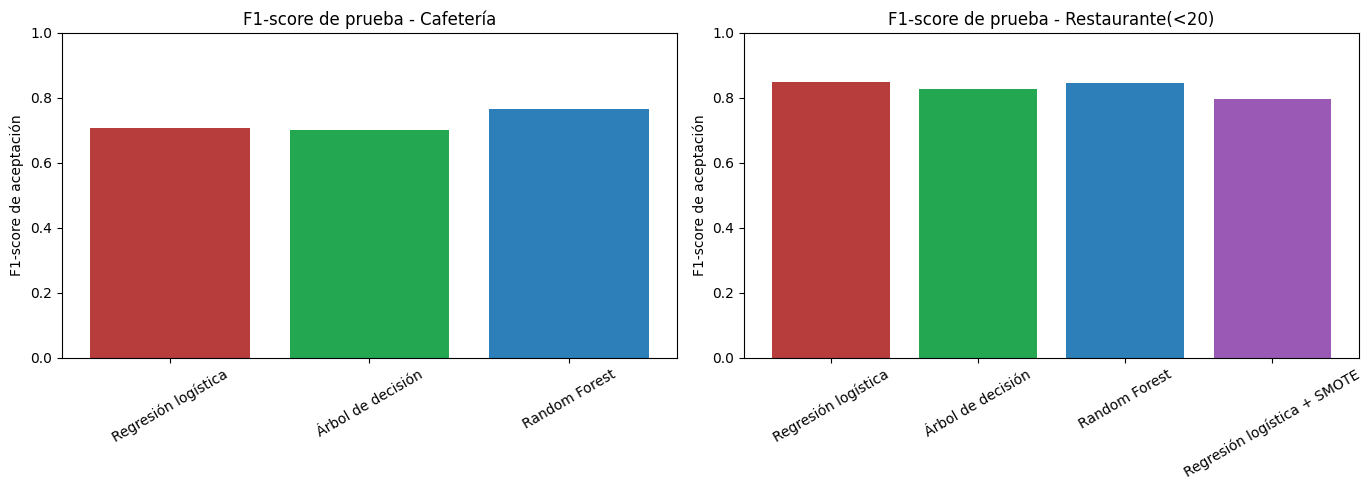

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, tabla, titulo in [
    (axes[0], tabla_caf, 'Cafetería'),
    (axes[1], tabla_res, 'Restaurante(<20)')
]:
    ax.bar(
        tabla['Modelo'],
        tabla['F1-score'],
        color=['#B73C3C', '#23A751', '#2C7FB8', '#9B59B6'][:len(tabla)]
    )

    ax.set_title(f'F1-score de prueba - {titulo}')
    ax.set_ylabel('F1-score de aceptación')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

#### 6.5. Comparación del efecto de SMOTE — Restaurante(<20)

Se comparan las versiones de regresión logística con y sin SMOTE, utilizando las mismas 21 variables predictoras y el mismo conjunto de prueba.

Además del F1-score de aceptación, se incluyen el F1-score macro y el recall de rechazo para mostrar el efecto del balanceo sobre ambas clases.

In [73]:
# Predicciones de los modelos
y_pred_sin_smote = grid_rl_res.predict(X_test_res)
y_pred_con_smote = grid_rl_res_smote.predict(X_test_res)

# Comparación de métricas
comparacion_smote = pd.DataFrame({
    'Modelo': ['Sin SMOTE', 'Con SMOTE'],
    'Accuracy': [
        accuracy_score(y_test_res, y_pred_sin_smote),
        accuracy_score(y_test_res, y_pred_con_smote)
    ],
    'Precision': [
        precision_score(y_test_res, y_pred_sin_smote),
        precision_score(y_test_res, y_pred_con_smote)
    ],
    'Recall (Sí)': [
        recall_score(y_test_res, y_pred_sin_smote),
        recall_score(y_test_res, y_pred_con_smote)
    ],
    'Recall (No)': [
        recall_score(y_test_res, y_pred_sin_smote, pos_label=0),
        recall_score(y_test_res, y_pred_con_smote, pos_label=0)
    ],
    'F1-score': [
        f1_score(y_test_res, y_pred_sin_smote),
        f1_score(y_test_res, y_pred_con_smote)
    ],
    'F1 macro': [
        f1_score(y_test_res, y_pred_sin_smote, average='macro'),
        f1_score(y_test_res, y_pred_con_smote, average='macro')
    ]
})

print(comparacion_smote.round(4).to_string(index=False))

   Modelo  Accuracy  Precision  Recall (Sí)  Recall (No)  F1-score  F1 macro
Sin SMOTE     0.769     0.7882       0.9209       0.4012    0.8494    0.6766
Con SMOTE     0.722     0.8287       0.7653       0.6173    0.7958    0.6804


#### Resultados de la comparación con SMOTE

El balanceo incrementó el recall de rechazo de 0,4012 a 0,6173, mientras que el recall de aceptación disminuyó de 0,9209 a 0,7602.

El F1-score de aceptación pasó de 0,8494 a 0,7926 y el F1-score macro cambió de 0,6766 a 0,6772.

Estos resultados muestran un intercambio entre la identificación de aceptaciones y rechazos. La recomendación para Ruta Alpes se completará en la pregunta 7.4, considerando el objetivo del sistema y la limitación de aplicar SMOTE sobre categorías codificadas.

#### Visualización del efecto de SMOTE sobre el recall

Se representa gráficamente el recall de aceptación y de rechazo obtenido por los modelos de regresión logística con y sin SMOTE.

Esta comparación permite observar el efecto del balanceo sobre la capacidad del clasificador para identificar correctamente cada clase, especialmente los rechazos, que constituyen la clase minoritaria de Restaurante(<20).

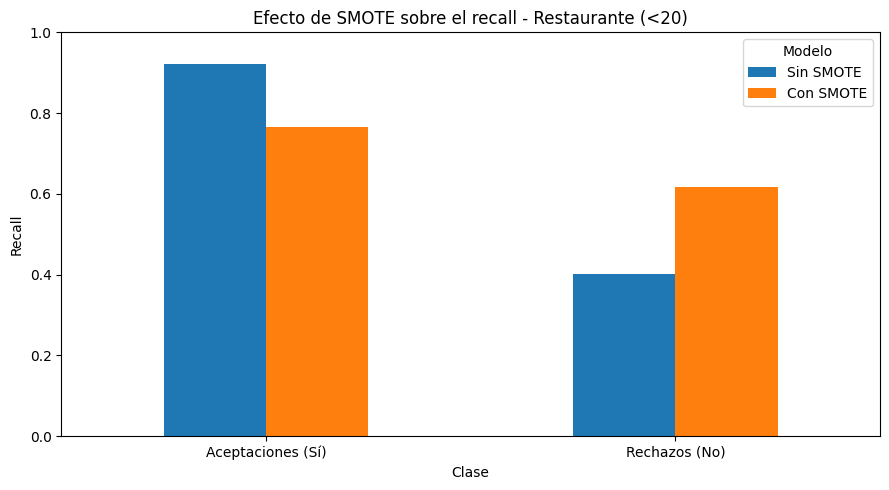

In [74]:
comparacion_recall = pd.DataFrame({
    'Sin SMOTE': [
        comparacion_smote.loc[0, 'Recall (Sí)'],
        comparacion_smote.loc[0, 'Recall (No)']
    ],
    'Con SMOTE': [
        comparacion_smote.loc[1, 'Recall (Sí)'],
        comparacion_smote.loc[1, 'Recall (No)']
    ]
}, index=['Aceptaciones (Sí)', 'Rechazos (No)'])

comparacion_recall.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Efecto de SMOTE sobre el recall - Restaurante (<20)')
plt.ylabel('Recall')
plt.xlabel('Clase')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Modelo')
plt.tight_layout()
plt.show()

## 7. Análisis de resultados

### 7.1. ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?

Para Cafetería, la frecuencia de visitas a cafeterías fue la variable con mayor importancia agrupada en Random Forest, con un valor de 0,1705. También destacaron ocupación, ingreso y edad. Al revisar las categorías individuales, sobresalieron quienes nunca visitan cafeterías, la vigencia del cupón de dos horas y el destino sin lugar urgente.

Para Restaurante(<20), las mayores importancias agrupadas correspondieron a ocupación, ingreso, hora y edad. Entre las características individuales destacaron la vigencia del cupón de dos horas, el destino sin lugar urgente y el tiempo de desplazamiento superior a 25 minutos.

Los resultados muestran que los modelos utilizan tanto hábitos y características del perfil como condiciones de la oferta y del recorrido. Sin embargo, las importancias no indican por sí solas si una característica aumenta o disminuye la aceptación. Además, pueden favorecer variables con muchas categorías y no deben interpretarse como relaciones causales.


### 7.2. ¿Existen variables que podrían ser redundantes o poco informativas?

Sí. La variable `cupon` es constante dentro de cada subconjunto y `tiempo_cupon_mayor_5min` toma el valor "Sí" en todos sus registros. Por tanto, no permiten distinguir entre aceptaciones y rechazos dentro de cada tipo de cupón.

También se eliminó `vehiculo`, porque presenta más del 99 % de valores faltantes. Por otra parte, se comprobó que `misma_direccion` y `direccion_opuesta` son complementarias, por lo que se conservó únicamente `misma_direccion`.

Después de estas exclusiones quedaron 21 variables predictoras. Los tiempos superiores a 15 y 25 minutos se mantuvieron porque, aunque están relacionados, representan condiciones diferentes del desplazamiento.


### 7.3. ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿a qué atribuye esa diferencia?

Sí. En Cafetería, el Random Forest seleccionado obtuvo un F1-score de aceptación de 0,7640 y un F1-score macro de 0,7560. En Restaurante(<20), estos valores fueron 0,8471 y 0,6716, respectivamente.

Aunque Restaurante presenta un mayor F1-score de aceptación, su desempeño entre clases es menos equilibrado. El recall de rechazo fue de 0,3951, frente a 0,7218 en Cafetería. Una posible explicación es que las aceptaciones representan aproximadamente el 70,7 % de los registros de Restaurante, mientras que en Cafetería las clases están prácticamente equilibradas.

También pueden influir las diferencias en el tamaño de los subconjuntos y en las relaciones entre sus características y la aceptación. Estas son posibles explicaciones, no causas demostradas.

Random Forest fue seleccionado para ambos cupones por validación cruzada. Sin embargo, en Restaurante la regresión logística obtuvo un F1-score de prueba ligeramente mayor, de 0,8494.


### 7.4. ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo? Justifique considerando tanto el F1-score general como el recall de la clase minoritaria.

El efecto de SMOTE dependió de la métrica considerada. En la regresión logística, el recall de rechazo aumentó de 0,4012 a 0,6173, una mejora de aproximadamente 21,60 puntos porcentuales. Esto permitió identificar una mayor proporción de la clase minoritaria.

Sin embargo, el F1-score de aceptación disminuyó de 0,8494 a 0,7926 y el recall de aceptación pasó de 0,9209 a 0,7602. El F1-score macro prácticamente se mantuvo, al cambiar de 0,6766 a 0,6772.

Con el criterio de selección utilizado en el laboratorio, que prioriza el F1-score de aceptación, recomendamos conservar la versión sin SMOTE. El balanceo podría considerarse si Ruta Alpes diera mayor importancia a detectar rechazos para reducir ofertas irrelevantes, aceptando que también dejaría de identificar algunas aceptaciones.

Esta recomendación corresponde al experimento realizado con regresión logística. Además, debe considerarse que SMOTE convencional puede generar valores intermedios entre las categorías codificadas mediante OneHotEncoder.


### 7.5. A partir de alguno de los modelos de árbol o Random Forest, describa en términos de reglas o de importancia de variables las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de esta interpretación.

En el árbol de Cafetería, la primera división utiliza la categoría `frecuencia_cafeteria_nunca`. Entre los registros de entrenamiento que pertenecen a esa categoría, aproximadamente el 18,3 % corresponde a aceptación. En el otro grupo, que también incluye los valores sin información, la aceptación es de aproximadamente el 59,3 %.

En el árbol de Restaurante(<20), la primera división considera si el desplazamiento supera los 25 minutos. La aceptación es de aproximadamente el 75,5 % cuando no se supera ese tiempo y del 32,4 % cuando sí se supera. Después, el árbol incorpora otras condiciones, como la hora y el acompañante.

Estas reglas permiten entender algunas condiciones utilizadas por los modelos y explicar sus decisiones de manera sencilla. Su limitación es que describen asociaciones del entrenamiento: no garantizan la respuesta de cada conductor ni demuestran que cambiar una característica cause un cambio en su decisión.


### 7.6. ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?

La aplicación podría utilizar el modelo previamente entrenado para el tipo de cupón que se está considerando. Con la información disponible del perfil y del contexto, como la hora, el destino, los hábitos de consumo y el tiempo de desplazamiento, aplicaría el mismo preprocesamiento utilizado durante el entrenamiento y estimaría la probabilidad de aceptación.

Esa estimación serviría para decidir si conviene mostrar la oferta, utilizando un criterio definido previamente con datos de validación. Durante el recorrido solamente sería necesario realizar la predicción.

También sería importante limitar las notificaciones para evitar distracciones y registrar nuevas respuestas de los usuarios. Con esa información se podría revisar el desempeño y actualizar periódicamente los modelos.


### 7.7. ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?

El perfil demográfico no describe por completo las preferencias de una persona. Conductores con la misma edad, ingreso o estado civil pueden tener intereses diferentes, y esas preferencias pueden cambiar según el contexto.

Un sistema que dependa demasiado de estas variables podría repetir estereotipos o limitar las ofertas que reciben ciertos grupos. También podría equivocarse cuando la información del perfil esté incompleta o desactualizada.

Por esta razón, sería conveniente permitir que los usuarios indiquen sus preferencias, limitar el uso de información personal a lo necesario y revisar el desempeño por grupos. Las decisiones del sistema deberían considerar los hábitos y el contexto, además del perfil demográfico.


### 7.8. ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso para personalizar ofertas? ¿Qué implicaciones tendría esta personalización si se usara para fines distintos a cupones, como precios dinámicos?

Podría existir sesgo de representación si algunos perfiles tienen pocos registros o si la muestra no refleja a los usuarios reales de Ruta Alpes. También podrían influir errores o limitaciones en la información reportada sobre los hábitos de consumo.

En el modelado, el desbalance de Restaurante(<20) y la selección mediante F1-score de aceptación pueden favorecer el reconocimiento de la clase mayoritaria. Los resultados muestran que identificar rechazos sigue siendo una dificultad, pero no se evaluó si los errores se distribuyen de manera desigual entre grupos demográficos.

Al utilizar edad, género, estado civil o ingreso, el modelo podría reproducir diferencias presentes en los datos. Por eso sería necesario revisar tanto la representación de los grupos como las métricas obtenidas para cada uno.

Si esta personalización se utilizara para precios dinámicos, sus consecuencias podrían ser mayores: una persona podría recibir precios distintos por su perfil o por una capacidad de pago estimada. Esto podría generar un trato desigual y reforzar desventajas, por lo que requeriría una evaluación adicional antes de utilizar el modelo con ese propósito.

## 8. Predicciones sobre los datos sin etiquetas

### 8.1. Ajuste de los modelos finales

Después de finalizar la evaluación, se conservan las configuraciones seleccionadas mediante validación cruzada y se ajustan con todos los datos etiquetados disponibles de cada cupón.

Se utilizan copias de los pipelines para conservar los modelos empleados en la evaluación. Las métricas reportadas anteriormente siguen correspondiendo a la partición original de entrenamiento y prueba.

In [75]:
modelo_final_caf = clone(
    modelos_caf[nombre_final_caf].best_estimator_
)

modelo_final_res = clone(
    modelos_res[nombre_final_res].best_estimator_
)

modelo_final_caf.fit(X_cafeteria, y_cafeteria)
modelo_final_res.fit(X_restaurante, y_restaurante)

print("Cafetería:", nombre_final_caf)
print("Registros utilizados:", len(X_cafeteria))

print("\nRestaurante(<20):", nombre_final_res)
print("Registros utilizados:", len(X_restaurante))

Cafetería: Random Forest
Registros utilizados: 3979

Restaurante(<20): Random Forest
Registros utilizados: 2769


### 8.2. Generación y exportación de las predicciones

Se carga `Lab3_datos_Prueba.xlsx` y se utiliza el modelo correspondiente al tipo de cupón de cada registro.

El archivo de salida conserva las columnas y el orden originales. Únicamente se añade `acepta_cupon`, con las etiquetas "Sí" y "No".

In [76]:
prueba_original = pd.read_excel(
    './Data/Lab3_datos_Prueba.xlsx'
)

assert prueba_original['cupon'].isin([
    'Cafetería',
    'Restaurante(<20)'
]).all()

resultado = prueba_original.copy()

resultado['acepta_cupon'] = pd.Series(
    index=resultado.index,
    dtype='object'
)

for tipo, modelo, columnas in [
    ('Cafetería', modelo_final_caf, X_cafeteria.columns),
    ('Restaurante(<20)', modelo_final_res, X_restaurante.columns)
]:
    mascara = prueba_original['cupon'].eq(tipo)

    predicciones = modelo.predict(
        prueba_original.loc[mascara, columnas]
    )

    etiquetas = pd.Series(
        predicciones,
        index=prueba_original.index[mascara]
    ).map({
        0: 'No',
        1: 'Sí'
    })

    resultado.loc[mascara, 'acepta_cupon'] = etiquetas

# Verificar las etiquetas y la conservación de los datos originales
assert resultado['acepta_cupon'].isin(['No', 'Sí']).all()

pd.testing.assert_frame_equal(
    resultado.drop(columns='acepta_cupon'),
    prueba_original
)

resultado.to_csv(
    'Lab3_datos_Prueba.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Archivo generado: Lab3_datos_Prueba.csv")
print("Dimensiones:", resultado.shape)

display(resultado[['cupon', 'acepta_cupon']])

display(pd.crosstab(
    resultado['cupon'],
    resultado['acepta_cupon']
))

Archivo generado: Lab3_datos_Prueba.csv
Dimensiones: (20, 26)


,cupon,acepta_cupon
0,Cafetería,No
1,Cafetería,Sí
2,Cafetería,Sí
3,Cafetería,Sí
4,Restaurante(<20),Sí
5,Restaurante(<20),Sí
6,Restaurante(<20),No
7,Restaurante(<20),Sí
8,Restaurante(<20),Sí
9,Cafetería,No


acepta_cupon,No,Sí
cupon,,
Cafetería,4,6
Restaurante(<20),1,9


## 9. Uso de herramientas de IA generativa

### Declaración del uso

Utilizamos ChatGPT como apoyo para revisar el notebook, resolver dudas de código, proponer correcciones y ayudar en la redacción de explicaciones y respuestas. 

### Prompts utilizados

Los principales prompts se resumen así:

- Revisar el notebook teniendo en cuenta el enunciado, la rúbrica y los materiales del semestre 202620.
- Identificar inconsistencias y señalar qué celdas corregir o agregar, conservando la estructura del trabajo.
- ayudar a comprobar que sea reproducible en otros dispositivos (esto porque estabamos teniendo errores con cosas de las graficas).
### Análisis crítico del resultado

**¿Qué partes del contenido generado fueron correctas y útiles?**

Lo más útil fue contar con apoyo para revisar la consistencia del trabajo e identificar aspectos que necesitaban corrección. También nos ayudó a resolver dudas puntuales de código y a comprobar que las explicaciones correspondieran con los resultados obtenidos.

En las gráficas, fue útil revisar que los valores se calcularan a partir de las predicciones del notebook, en lugar de escribirlos manualmente. Esto facilita que las visualizaciones se actualicen al ejecutar nuevamente el código.

**¿Qué limitaciones identificamos y cómo evaluamos las recomendaciones?**

Durante la revisión general, algunas recomendaciones buscaban reducir la extensión del notebook porque consideraban que ciertas partes estaban sobreexplicadas. Sin embargo, consideramos necesario conservar las explicaciones que justificaban las decisiones y permitían entender el procedimiento a alguien con conocimientos básicos de Machine Learning.

Por esta razón, evaluamos las sugerencias según el propósito y los requisitos del laboratorio. Mantuvimos el nivel de explicación que consideramos necesario, procurando que los textos fueran claros y estuvieran relacionados con las salidas del código.

### Aportes propios y aprendizajes

Partimos del notebook que veníamos trabajando, aplicamos los ajustes y lo ejecutamos nuevamente para revisar los resultados. También definimos que el documento debía conservar una estructura explicativa, con justificaciones suficientes para seguir el proceso de preparación, entrenamiento y evaluación.

La revisión nos ayudó a comprender mejor cómo comparar los modelos, la diferencia entre seleccionar mediante validación cruzada y evaluar sobre prueba, y el efecto de SMOTE sobre las distintas métricas. Además, reforzamos la importancia de construir las gráficas directamente desde los resultados y de actualizar las interpretaciones cuando se modifica el código.